# Model Training and Evaluation

Comparing supervised classifiers for medication adherence prediction.


In [1]:
# Standard imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Data preparation
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score

# Feature selection
from sklearn.feature_selection import SelectKBest, f_classif

# Scaling & dimensionality reduction
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score,
    RocCurveDisplay, ConfusionMatrixDisplay
)

This notebook combines the team's individual model experiments into one workflow. Run `01_preprocessing.ipynb` first to generate the processed dataset.


In [ ]:
# Load data prepared by the preprocessing notebook
from pathlib import Path

project_root = next(
    (folder for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / "data" / "raw" / "medication_adherence.xlsx").is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Could not locate the project root. Open Jupyter from the project directory.")

csv_path = project_root / "data" / "processed" / "preprocessed_dataset.csv"
if not csv_path.exists():
    raise FileNotFoundError("Preprocessed data not found. Run notebooks/01_preprocessing.ipynb first.")
df = pd.read_csv(csv_path)
target = "ADHERENCE"
X = df.drop(columns=[target])
y = df[target].astype(int)

print(X.shape, y.mean())

# Stratified 80/20 train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)


Evaluation Functions

In [3]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

def evaluate_model(y_true, y_pred, y_prob, name="Model"):
    # Metrics
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred)
    rec = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    auc = roc_auc_score(y_true, y_prob)

    print(f"\n===== {name} =====")
    print(f"Accuracy:  {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall:    {rec:.4f}")
    print(f"F1 Score:  {f1:.4f}")
    print(f"AUC:       {auc:.4f}\n")

    # Define confusion matrix BEFORE printing
    cm = confusion_matrix(y_true, y_pred)

    print("Confusion Matrix:")
    print(cm)

    print("\nClassification Report:")
    print(classification_report(y_true, y_pred))

    # Heatmap
    disp = ConfusionMatrixDisplay(confusion_matrix=cm)
    disp.plot(cmap='Blues')
    plt.title(f"Confusion Matrix — {name}")
    plt.show()


#1. KNN (Omar Aloruk)

Classifier Import

In [4]:
# Classifier
from sklearn.neighbors import KNeighborsClassifier

Baseline KNN (k=5, Euclidean)


===== Baseline KNN =====
Accuracy:  0.7851
Precision: 0.7072
Recall:    0.7932
F1 Score:  0.7477
AUC:       0.8564

Confusion Matrix:
[[2248  635]
 [ 400 1534]]

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.78      0.81      2883
           1       0.71      0.79      0.75      1934

    accuracy                           0.79      4817
   macro avg       0.78      0.79      0.78      4817
weighted avg       0.79      0.79      0.79      4817



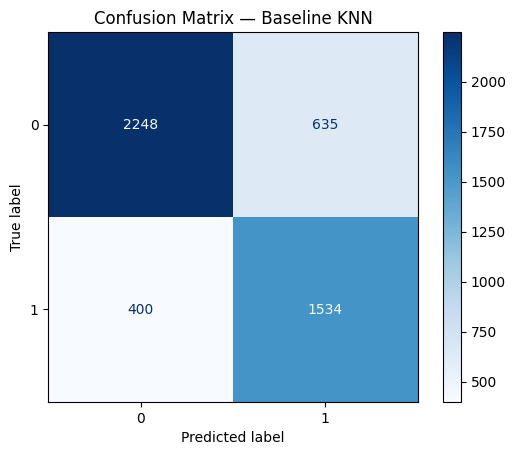

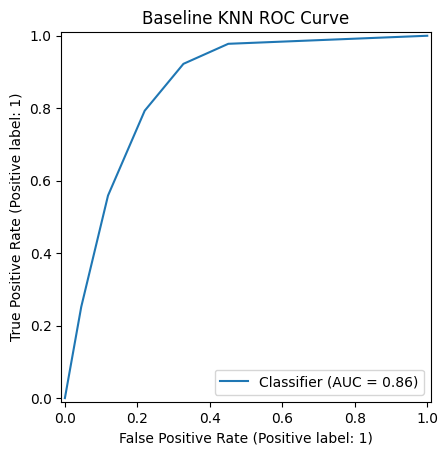

In [5]:
baseline_knn = KNeighborsClassifier(
    n_neighbors=5,
    weights='uniform',
    p=2  # Euclidean distance
)

baseline_knn.fit(X_train, y_train)

y_pred_base = baseline_knn.predict(X_test)
y_prob_base = baseline_knn.predict_proba(X_test)[:, 1]

evaluate_model(y_test, y_pred_base, y_prob_base, "Baseline KNN")

RocCurveDisplay.from_predictions(y_test, y_prob_base)
plt.title("Baseline KNN ROC Curve")
plt.show()

Hyperparameter Tuning

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def cv_train_val_accuracy(model, X, y):
  train_scores = []
  val_scores = []

  for train_idx, val_idx in cv.split(X, y):
    X_tr, X_val = X.iloc[train_idx], X.iloc[val_idx]
    y_tr, y_val = y.iloc[train_idx], y.iloc[val_idx]

    model.fit(X_tr, y_tr)

    # Training accuracy for this fold
    train_scores.append(accuracy_score(y_tr, model.predict(X_tr)))

    # Validation accuracy for this fold
    val_scores.append(accuracy_score(y_val, model.predict(X_val)))

  return np.mean(train_scores), np.mean(val_scores)

In [7]:
k_values = list(range(3, 64, 2)) # range of k values to test
weight_options = ["uniform", "distance"]
p_options = [1, 2] # 1 - Manhattan, 2 - Euclidean

In [9]:
# Storage
results = []
best_score = -1
best_params = None

# Train KNN for every combination + store train/test accuracy
for w in weight_options:
    for p in p_options:

        train_acc_list = []
        val_acc_list = []

        for k in k_values:
            model = KNeighborsClassifier(
                n_neighbors=k,
                weights=w,
                p=p
            )

            train_acc, val_acc = cv_train_val_accuracy(model, X_train, y_train)

            train_acc_list.append(train_acc)
            val_acc_list.append(val_acc)

            if val_acc > best_score:
                best_score = val_acc
                best_params = {"n_neighbors": k, "weights": w, "p": p}

        results.append({
            "weights": w,
            "p": p,
            "train_acc": train_acc_list,
            "val_acc": val_acc_list
        })

Hyperparameter Plot (Train vs Validation)

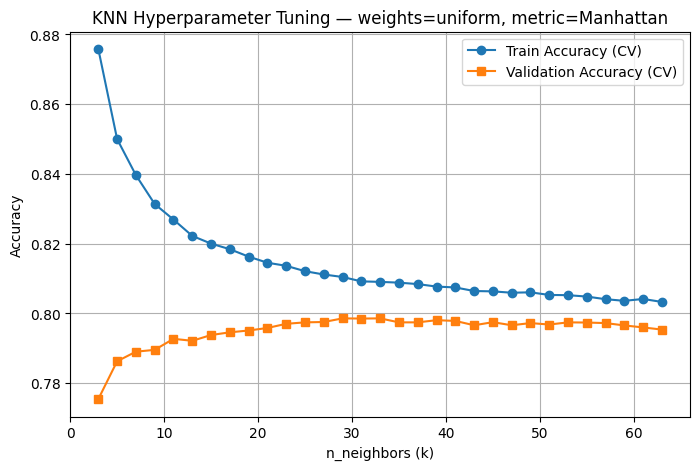

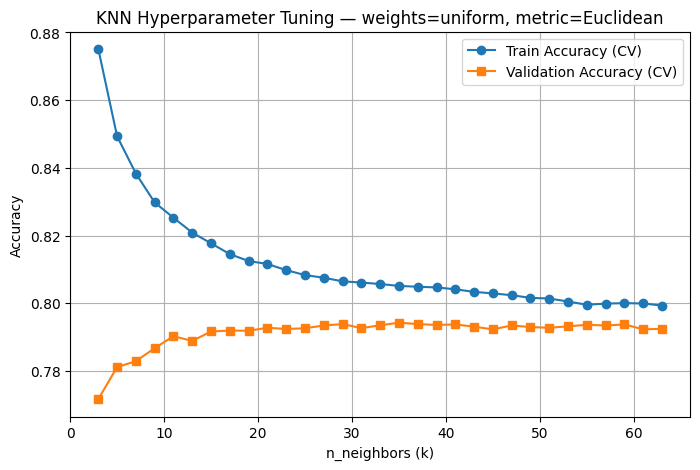

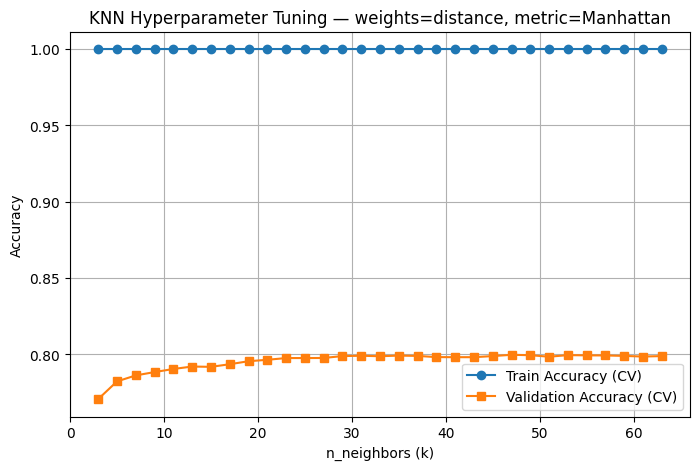

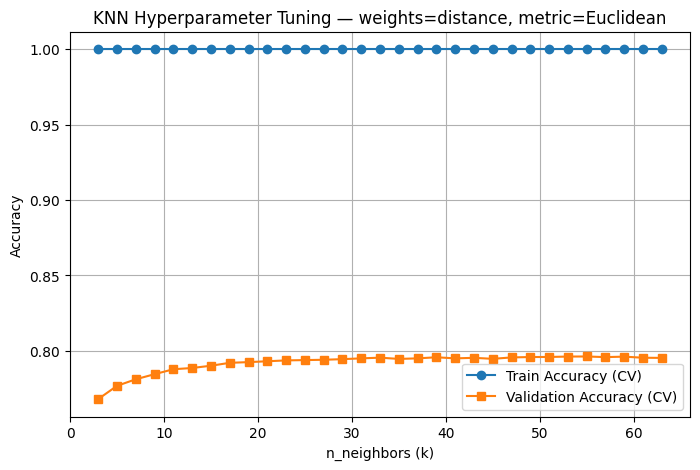

In [10]:
for res in results:
    w = res["weights"]
    p = res["p"]

    metric_name = "Euclidean" if p == 2 else "Manhattan"

    plt.figure(figsize=(8,5))
    plt.plot(k_values, res["train_acc"], marker='o', label='Train Accuracy (CV)')
    plt.plot(k_values, res["val_acc"],  marker='s', label='Validation Accuracy (CV)')

    plt.title(f"KNN Hyperparameter Tuning — weights={w}, metric={metric_name}")
    plt.xlabel("n_neighbors (k)")
    plt.ylabel("Accuracy")
    plt.grid(True)
    plt.legend()
    plt.show()

In [12]:
# Evaluate ALL trained KNN combinations saved in `results`
best_overall_params = None
best_overall_score = -1

for res in results:
    w = res["weights"]
    p = res["p"]
    val_acc_list = res["val_acc"]

    # Identify best k within this combination
    max_idx = np.argmax(val_acc_list)
    best_k = k_values[max_idx]
    best_val = val_acc_list[max_idx]

    # Track best across ALL combinations
    if best_val > best_overall_score:
        best_overall_score = best_val
        best_overall_params = {
            "n_neighbors": best_k,
            "weights": w,
            "p": p
        }

print("BEST KNN MODEL (All combinations):")
print(best_overall_params)
print("Validation Accuracy:", round(best_overall_score, 4))


BEST KNN MODEL (All combinations):
{'n_neighbors': 47, 'weights': 'distance', 'p': 1}
Validation Accuracy: 0.7997


Tuned KNN Evaluation

Evaluation of Best Tuned KNN:

===== Best Tuned KNN =====
Accuracy:  0.7997
Precision: 0.7054
Recall:    0.8604
F1 Score:  0.7752
AUC:       0.8839

Confusion Matrix:
[[2188  695]
 [ 270 1664]]

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.76      0.82      2883
           1       0.71      0.86      0.78      1934

    accuracy                           0.80      4817
   macro avg       0.80      0.81      0.80      4817
weighted avg       0.82      0.80      0.80      4817



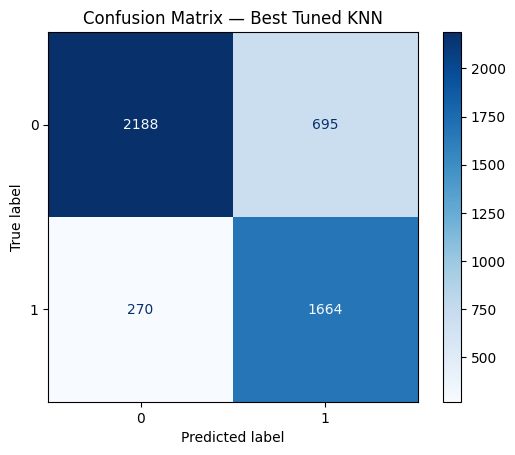

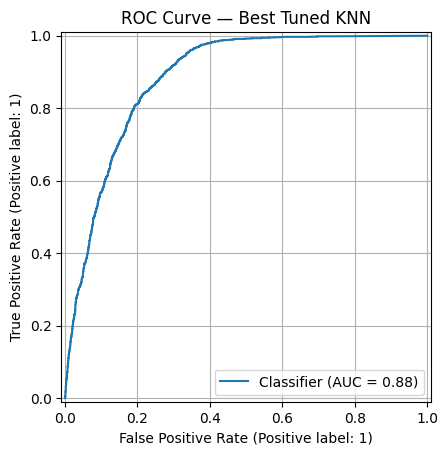

In [14]:
# Build tuned KNN model using the best overall parameters
best_knn = KNeighborsClassifier(
    n_neighbors=best_overall_params["n_neighbors"],
    weights=best_overall_params["weights"],
    p=best_overall_params["p"]
)

# Train the model
best_knn.fit(X_train, y_train)

# Evaluate on test set
y_pred = best_knn.predict(X_test)
y_prob = best_knn.predict_proba(X_test)[:, 1]

print("Evaluation of Best Tuned KNN:")
evaluate_model(y_test, y_pred, y_prob, name="Best Tuned KNN")

# Plot ROC curve
RocCurveDisplay.from_predictions(y_test, y_prob)
plt.title("ROC Curve — Best Tuned KNN")
plt.grid(True)
plt.show()


Feature selection

In [22]:
# Find the best number of features using SelectKBest

max_features = X_train.shape[1]
fs_val_scores = []

for k in range(1, max_features + 1):
  selector = SelectKBest(f_classif, k=k)
  X_train_k = selector.fit_transform(X_train, y_train)

  # Only uniform weights (stable)
  model = KNeighborsClassifier(n_neighbors=5, weights="uniform", p=2)

  # CV accuracy
  _, val_acc = cv_train_val_accuracy(model, pd.DataFrame(X_train_k), y_train)
  fs_val_scores.append(val_acc)

# Best number of features
best_k_features = np.argmax(fs_val_scores) + 1
print("Best number of features based on CV validation accuracy:", best_k_features)



Best number of features based on CV validation accuracy: 2


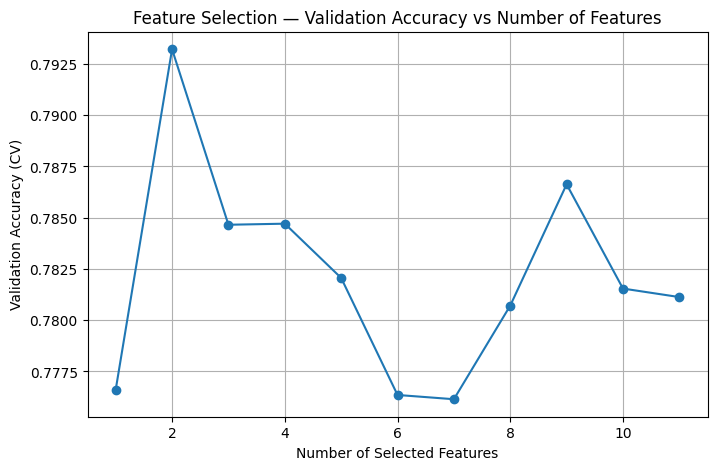

In [23]:
# Plotting the FS Curve
plt.figure(figsize=(8,5))
plt.plot(range(1, max_features + 1), fs_val_scores, marker='o')
plt.xlabel("Number of Selected Features")
plt.ylabel("Validation Accuracy (CV)")
plt.title("Feature Selection — Validation Accuracy vs Number of Features")
plt.grid(True)
plt.show()

In [24]:
# Hyperparameter tuning in FS space
k_values = list(range(3, 64, 2))  # same k range
p_options = [1, 2]                # Manhattan & Euclidean
weight_options = ["uniform", "distance"]

best_fs_score = -1
best_fs_params = None

fs_results = []   # For plotting later

for f in range(1, best_k_features + 1):
    # Select top-f features
    selector = SelectKBest(f_classif, k=f)
    X_train_f = selector.fit_transform(X_train, y_train)
    X_train_f = pd.DataFrame(X_train_f)

    # For plotting accuracy curves
    train_acc_list = []
    val_acc_list = []

    for k in k_values:
        for p in p_options:
            for w in weight_options:

                model = KNeighborsClassifier(
                    n_neighbors=k,
                    weights=w,
                    p=p
                )

                train_acc, val_acc = cv_train_val_accuracy(
                    model,
                    X_train_f,
                    y_train
                )

                train_acc_list.append(train_acc)
                val_acc_list.append(val_acc)

                # Track global best
                if val_acc > best_fs_score:
                    best_fs_score = val_acc
                    best_fs_params = {
                        "n_features": f,
                        "n_neighbors": k,
                        "p": p,
                        "weights": w,
                        "selector": selector
                    }

    fs_results.append({
        "n_features": f,
        "train_acc": train_acc_list,
        "val_acc": val_acc_list
    })

print("\nBest parameters after Feature Selection:")
print(best_fs_params)
print("Best FS Validation Accuracy:", round(best_fs_score, 4))



Best parameters after Feature Selection:
{'n_features': 2, 'n_neighbors': 53, 'p': 1, 'weights': 'uniform', 'selector': SelectKBest(k=2)}
Best FS Validation Accuracy: 0.8103


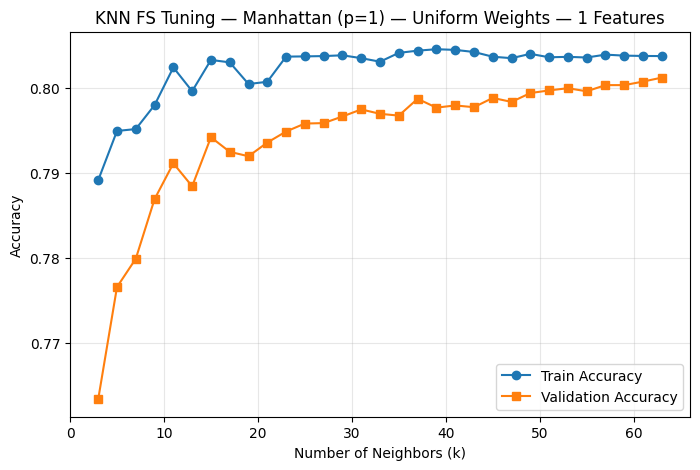

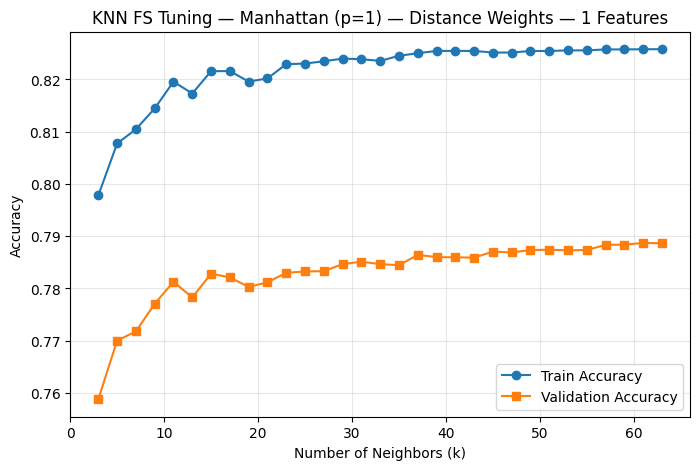

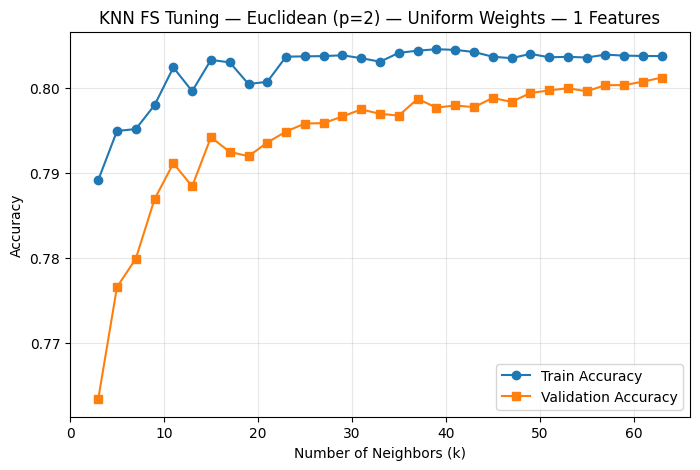

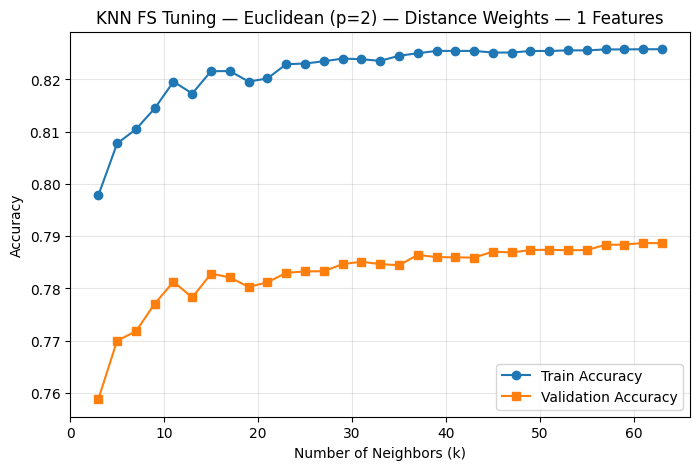

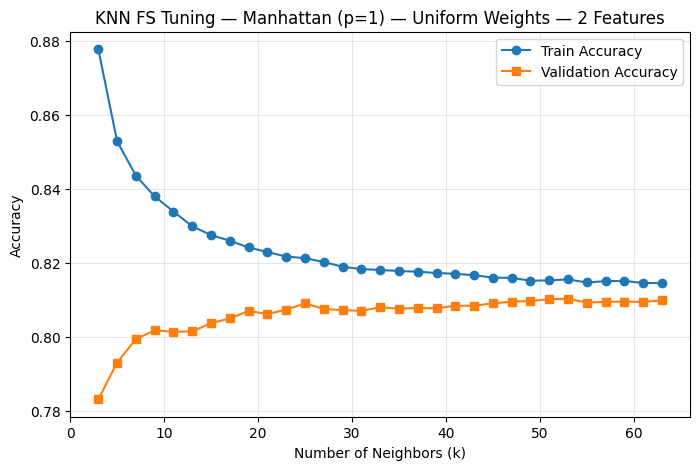

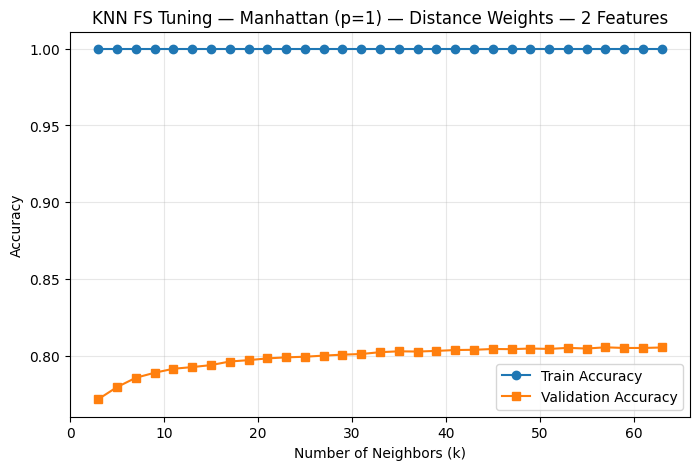

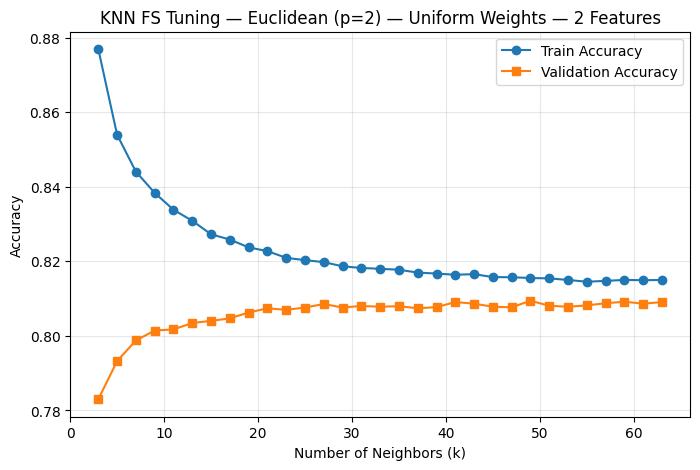

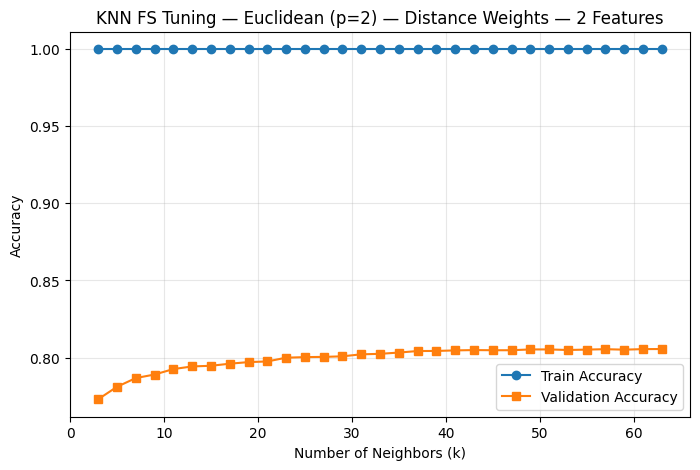

In [28]:
# Plot ALL four combinations (8 plots total if 2 feature subsets)
combos_per_f = len(p_options) * len(weight_options)  # = 4

labels = [
    "Manhattan (p=1) — Uniform Weights",
    "Manhattan (p=1) — Distance Weights",
    "Euclidean (p=2) — Uniform Weights",
    "Euclidean (p=2) — Distance Weights"
]

for result in fs_results:
    f = result["n_features"]
    train_acc = np.array(result["train_acc"])
    val_acc = np.array(result["val_acc"])

    # Reshape into (num_k_values, 4)
    train_acc = train_acc.reshape(len(k_values), combos_per_f)
    val_acc = val_acc.reshape(len(k_values), combos_per_f)

    # Plot 4 combinations for this feature count
    for idx in range(combos_per_f):
        plt.figure(figsize=(8, 5))
        plt.plot(k_values, train_acc[:, idx], marker='o', label="Train Accuracy")
        plt.plot(k_values, val_acc[:, idx], marker='s', label="Validation Accuracy")

        plt.title(f"KNN FS Tuning — {labels[idx]} — {f} Features")
        plt.xlabel("Number of Neighbors (k)")
        plt.ylabel("Accuracy")
        plt.grid(True, alpha=0.3)
        plt.legend()
        plt.show()



Evaluation of Best FS-Optimized KNN Model:

===== Best FS-Optimized KNN =====
Accuracy:  0.8059
Precision: 0.7134
Recall:    0.8635
F1 Score:  0.7813
AUC:       0.8878

Confusion Matrix:
[[2212  671]
 [ 264 1670]]

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.77      0.83      2883
           1       0.71      0.86      0.78      1934

    accuracy                           0.81      4817
   macro avg       0.80      0.82      0.80      4817
weighted avg       0.82      0.81      0.81      4817



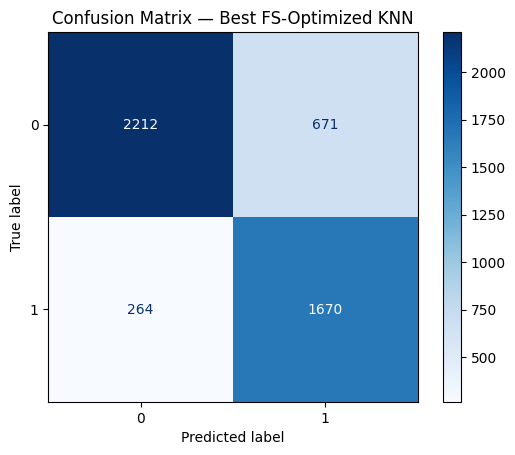

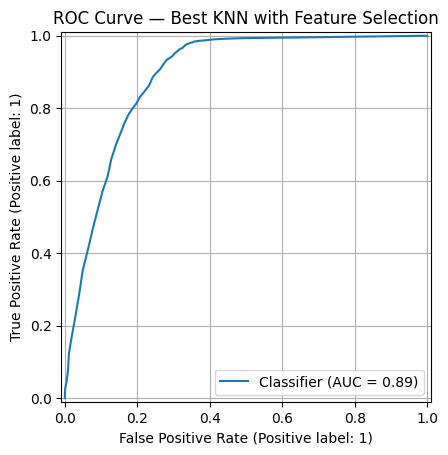

In [29]:
# Train and Evaluate Final FS-Optimised KNN Model

# Extract best FS selector & params
best_selector = best_fs_params["selector"]
X_train_fs = best_selector.transform(X_train)
X_test_fs  = best_selector.transform(X_test)

best_knn_fs = KNeighborsClassifier(
    n_neighbors = best_fs_params["n_neighbors"],
    weights     = best_fs_params["weights"],
    p           = best_fs_params["p"]
)

# Train on full training set
best_knn_fs.fit(X_train_fs, y_train)

# Evaluate on test set
y_pred_fs = best_knn_fs.predict(X_test_fs)
y_prob_fs = best_knn_fs.predict_proba(X_test_fs)[:, 1]

print("\nEvaluation of Best FS-Optimized KNN Model:")
evaluate_model(y_test, y_pred_fs, y_prob_fs, name="Best FS-Optimized KNN")

# ROC curve
RocCurveDisplay.from_predictions(y_test, y_prob_fs)
plt.title("ROC Curve — Best KNN with Feature Selection")
plt.grid(True)
plt.show()


Simple PCA (>= 90% variance)

Components for ≥90% variance: 6


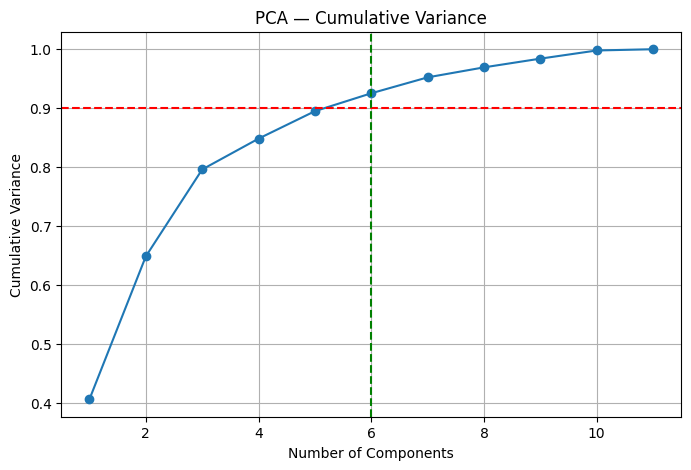

In [30]:
# PCA fit and curve
pca_full = PCA().fit(X_train)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)

# Find number of components ≥ 90%
n_components_90 = np.argmax(cum_var >= 0.90) + 1
print("Components for ≥90% variance:", n_components_90)

# Plot cumulative variance
plt.figure(figsize=(8,5))
plt.plot(range(1, len(cum_var) + 1), cum_var, marker='o')
plt.axhline(0.90, color='red', linestyle='--')
plt.axvline(n_components_90, color='green', linestyle='--')
plt.title("PCA — Cumulative Variance")
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Variance")
plt.grid(True)
plt.show()

In [31]:
# PCA hyperparameter tuning with both uniform and distance weights

best_pca_score = -1
best_pca_params = None
pca_results = []

p_options = [1, 2]                  # Manhattan, Euclidean
k_values = list(range(3, 64, 2))    # same k range
weight_options = ["uniform", "distance"]

for n in range(1, n_components_90 + 1):
    pca_n = PCA(n_components=n)
    X_train_pca_n = pca_n.fit_transform(X_train)
    X_train_pca_n = pd.DataFrame(X_train_pca_n, index=X_train.index)

    train_acc_list = []
    val_acc_list = []

    for k in k_values:
        for p in p_options:
            for w in weight_options:

                model = KNeighborsClassifier(
                    n_neighbors=k,
                    weights=w,
                    p=p
                )

                train_acc, val_acc = cv_train_val_accuracy(
                    model,
                    X_train_pca_n,
                    y_train
                )

                train_acc_list.append(train_acc)
                val_acc_list.append(val_acc)

                # Track global best PCA combination
                if val_acc > best_pca_score:
                    best_pca_score = val_acc
                    best_pca_params = {
                        "n_components": n,
                        "n_neighbors": k,
                        "p": p,
                        "weights": w,
                        "pca_model": pca_n
                    }

    # Store results for plotting
    pca_results.append({
        "n_components": n,
        "train_acc": train_acc_list,
        "val_acc": val_acc_list
    })

print("\nBest PCA parameters:")
print(best_pca_params)
print("Best PCA validation accuracy:", round(best_pca_score, 4))



Best PCA parameters:
{'n_components': 6, 'n_neighbors': 61, 'p': 2, 'weights': 'distance', 'pca_model': PCA(n_components=6)}
Best PCA validation accuracy: 0.7944


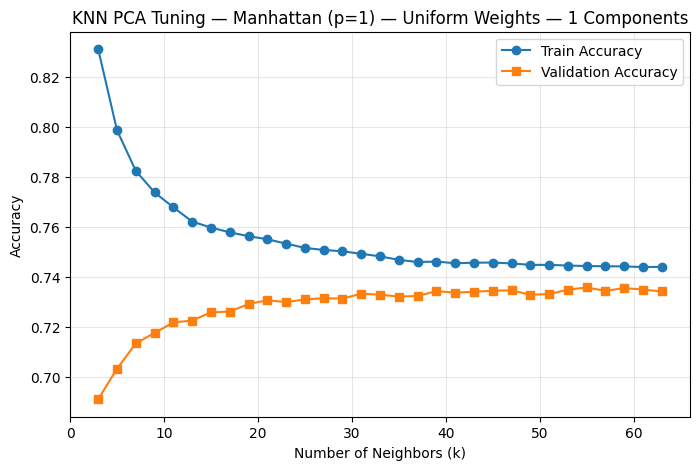

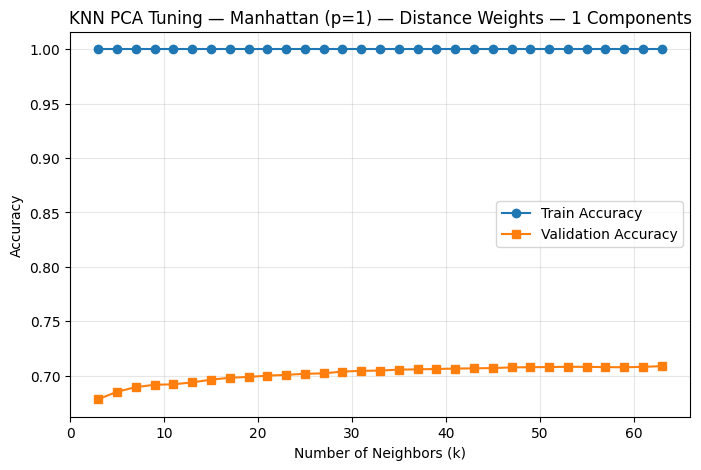

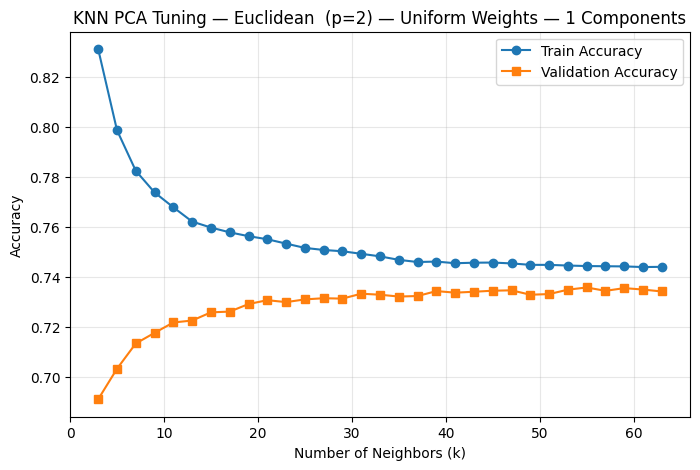

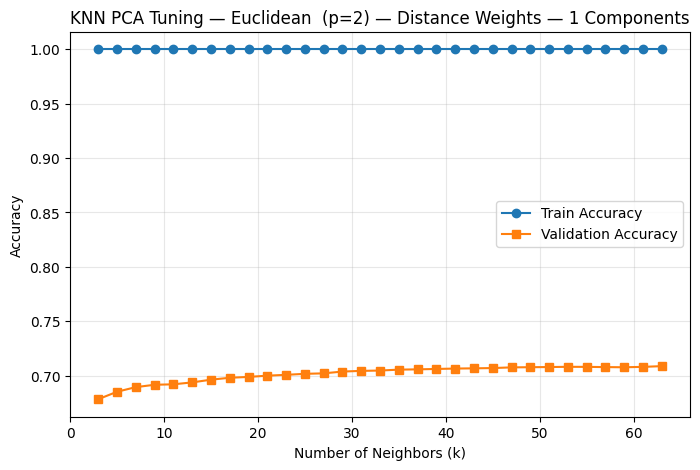

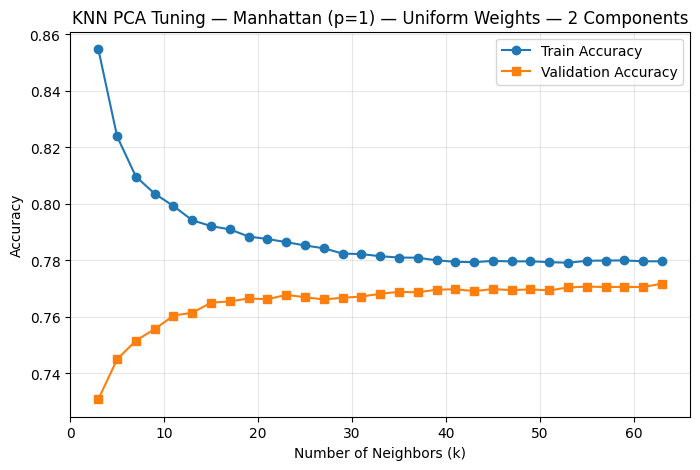

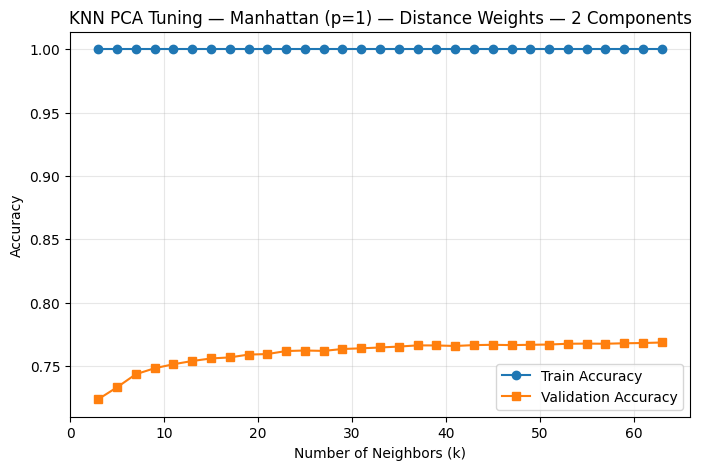

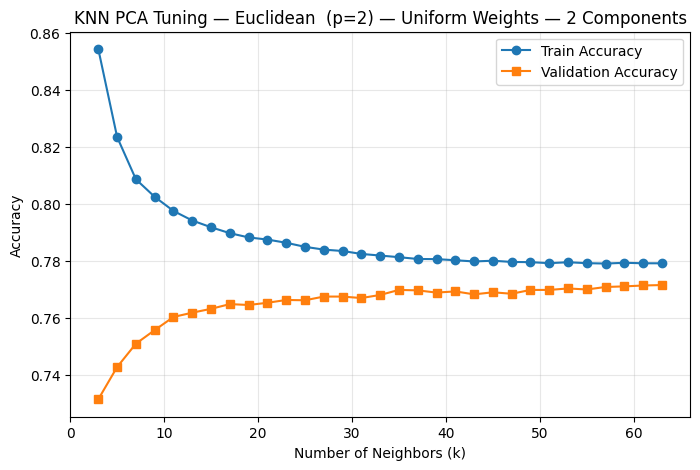

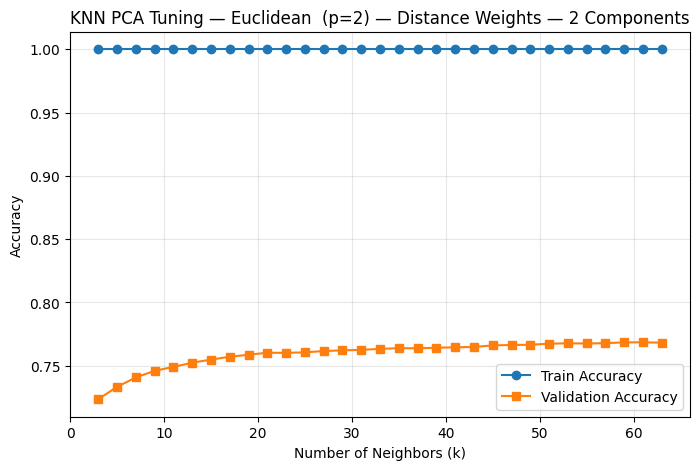

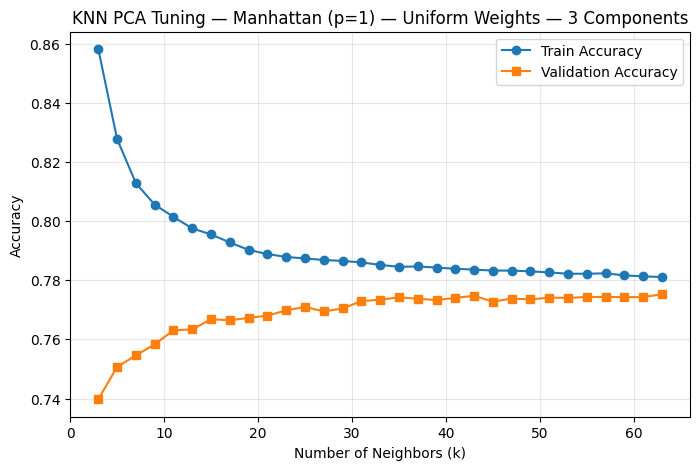

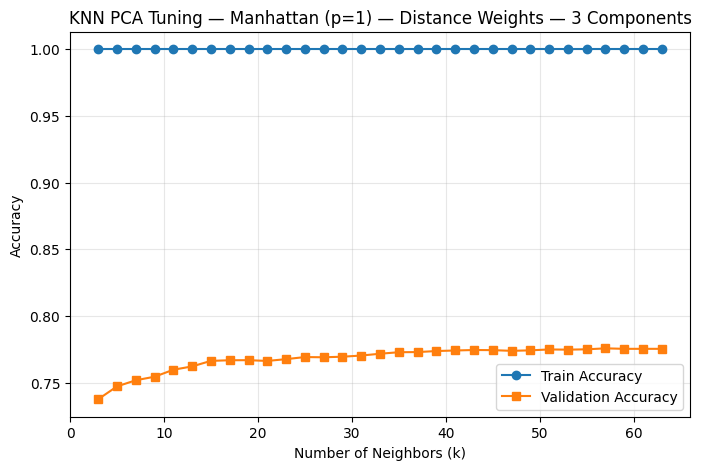

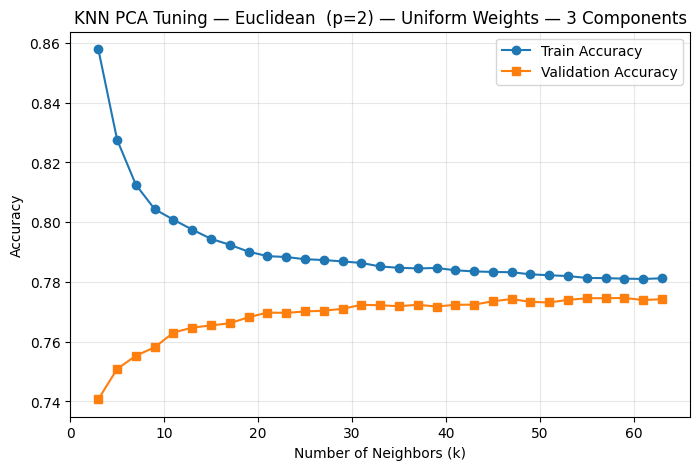

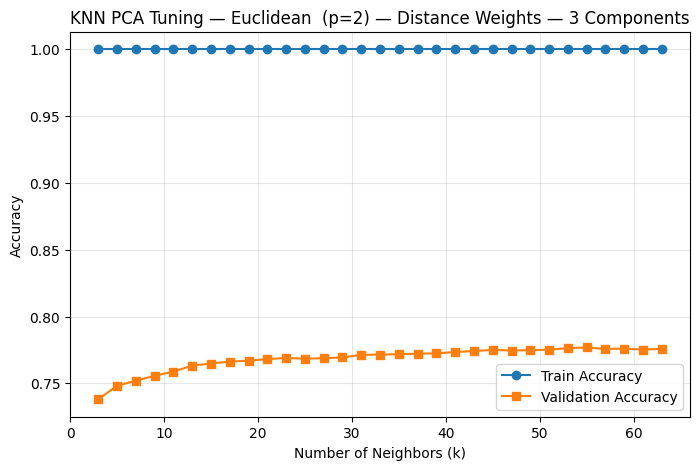

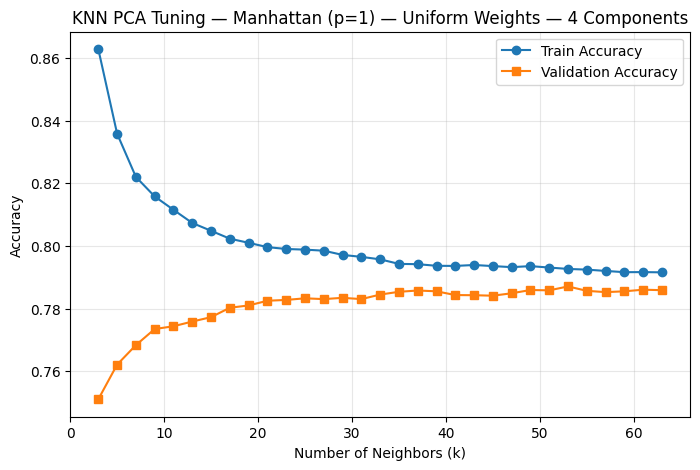

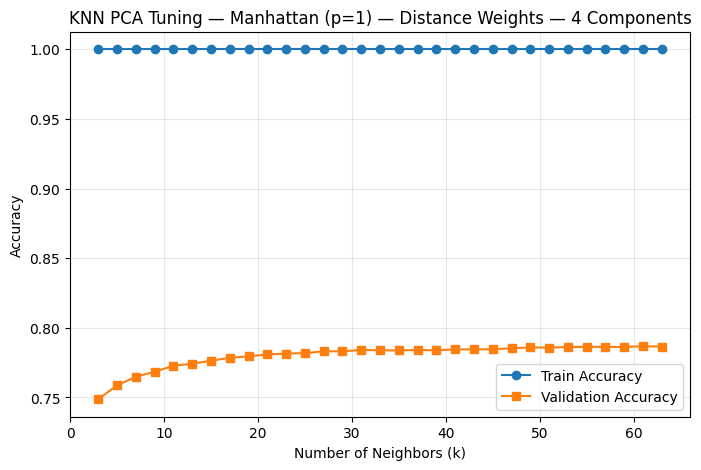

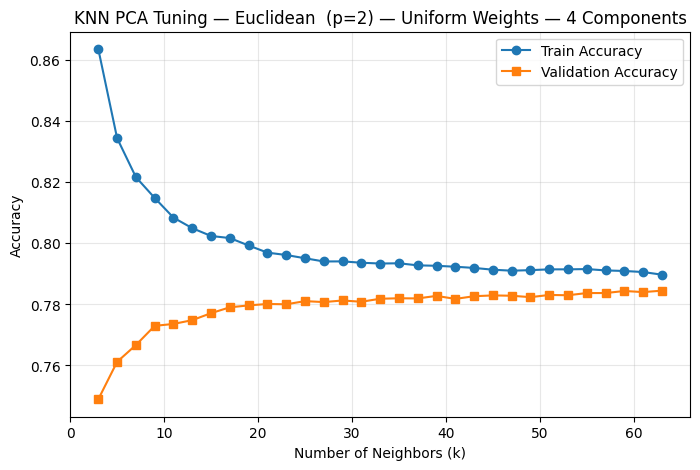

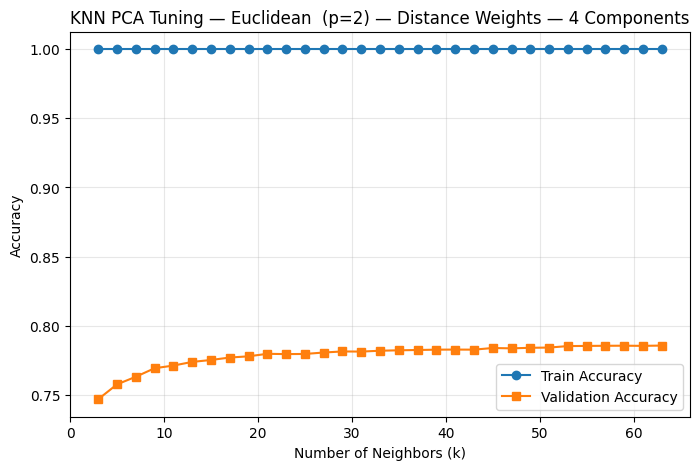

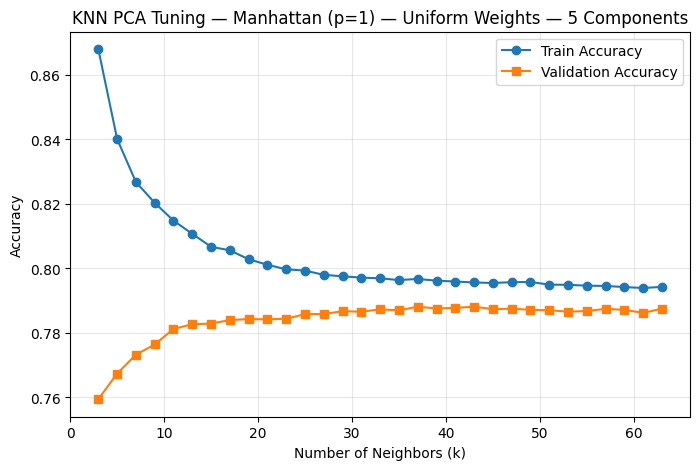

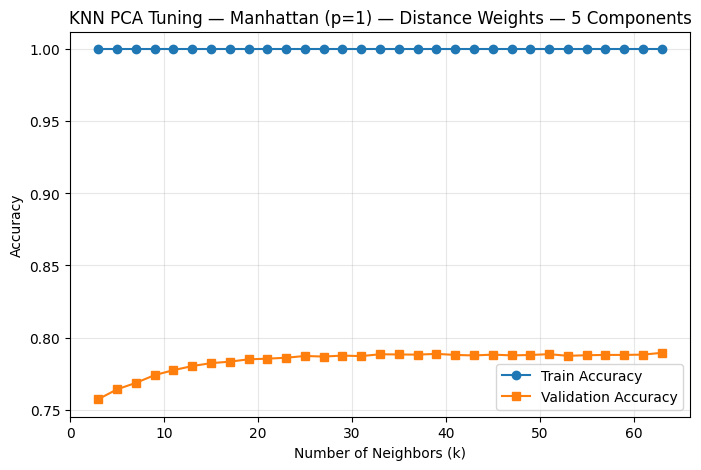

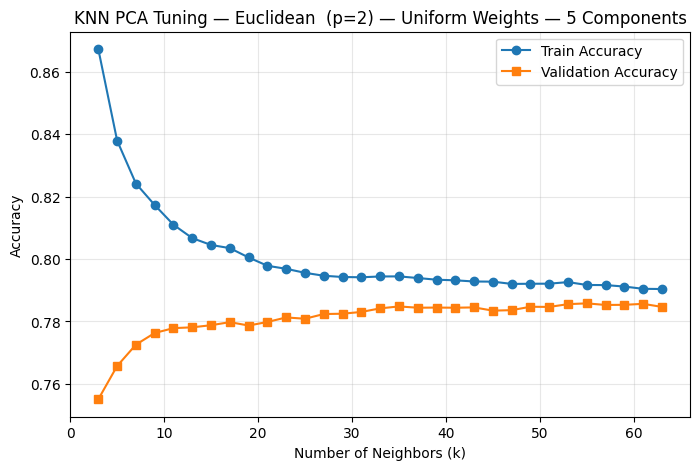

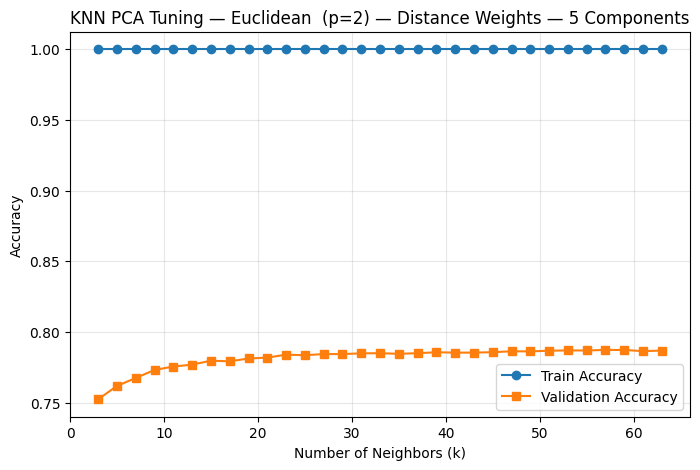

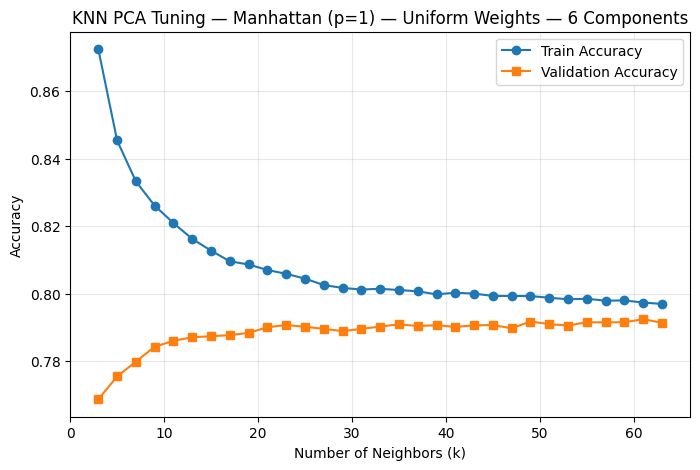

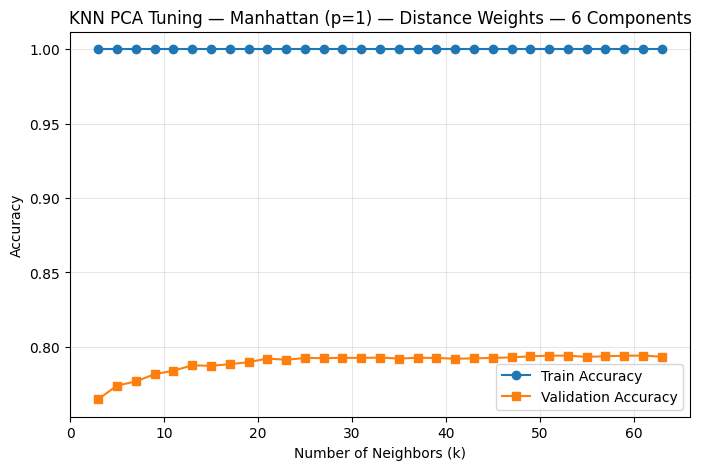

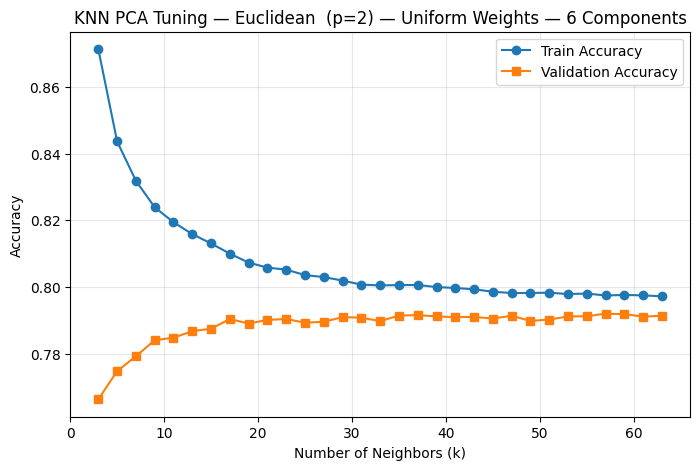

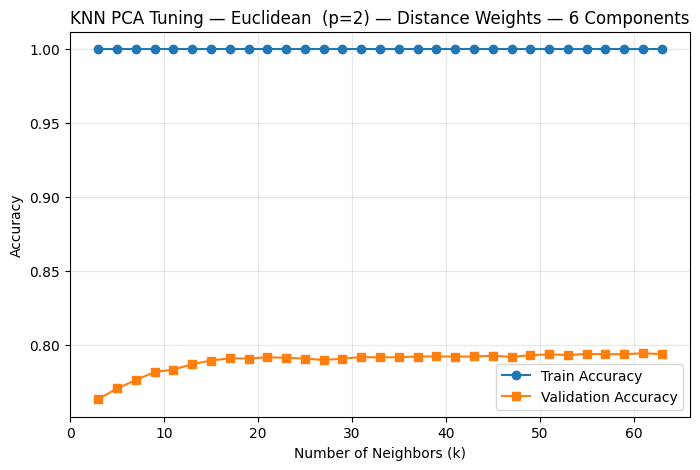

In [32]:
# Plot ALL four combinations (4 plots for each PCA component count)
combos_per_n = len(p_options) * len(weight_options)  # = 4

labels = [
    "Manhattan (p=1) — Uniform Weights",
    "Manhattan (p=1) — Distance Weights",
    "Euclidean  (p=2) — Uniform Weights",
    "Euclidean  (p=2) — Distance Weights"
]

for result in pca_results:
    n = result["n_components"]
    train_acc = np.array(result["train_acc"])
    val_acc = np.array(result["val_acc"])

    # Reshape into (num_k_values, 4 combos)
    train_acc = train_acc.reshape(len(k_values), combos_per_n)
    val_acc = val_acc.reshape(len(k_values), combos_per_n)

    # Plot the 4 combinations
    for idx in range(combos_per_n):
        plt.figure(figsize=(8, 5))
        plt.plot(k_values, train_acc[:, idx], marker='o', label="Train Accuracy")
        plt.plot(k_values, val_acc[:, idx], marker='s', label="Validation Accuracy")

        plt.title(f"KNN PCA Tuning — {labels[idx]} — {n} Components")
        plt.xlabel("Number of Neighbors (k)")
        plt.ylabel("Accuracy")
        plt.grid(True, alpha=0.3)
        plt.legend()
        plt.show()



===== KNN + PCA (6 components) =====
Accuracy:  0.7907
Precision: 0.6916
Recall:    0.8640
F1 Score:  0.7683
AUC:       0.8723

Confusion Matrix:
[[2138  745]
 [ 263 1671]]

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.74      0.81      2883
           1       0.69      0.86      0.77      1934

    accuracy                           0.79      4817
   macro avg       0.79      0.80      0.79      4817
weighted avg       0.81      0.79      0.79      4817



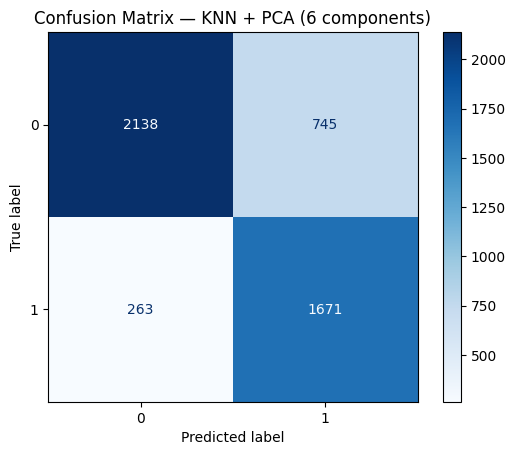

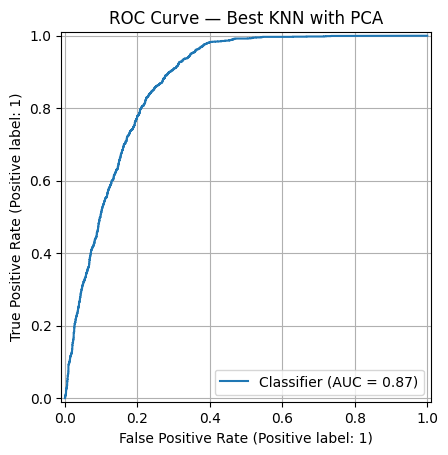

In [34]:
# Train + evaluate final PCA-optimised KNN
best_pca = best_pca_params["pca_model"]

# Fit PCA on full training set and transform both sets
best_pca.fit(X_train)
X_train_pca_final = best_pca.transform(X_train)
X_test_pca_final  = best_pca.transform(X_test)

# Build final KNN model with tuned parameters
best_knn_pca = KNeighborsClassifier(
    n_neighbors = best_pca_params["n_neighbors"],
    weights     = best_pca_params["weights"],   # FIXED
    p           = best_pca_params["p"]
)

# Train final model
best_knn_pca.fit(X_train_pca_final, y_train)

# Evaluate
y_pred_pca = best_knn_pca.predict(X_test_pca_final)
y_prob_pca = best_knn_pca.predict_proba(X_test_pca_final)[:, 1]

evaluate_model(
    y_test,
    y_pred_pca,
    y_prob_pca,
    f"KNN + PCA ({best_pca_params['n_components']} components)"
)

# ROC curve
RocCurveDisplay.from_predictions(y_test, y_prob_pca)
plt.title("ROC Curve — Best KNN with PCA")
plt.grid(True)
plt.show()


##Summary:
The KNN model initially achieved moderate accuracy in its baseline form, but performance improved noticeably after hyperparameter tuning and dimensionality reduction. Using 5-fold cross-validation, the best configuration was obtained under uniform weighting, where the optimal combination of neighbors and distance metric produced higher validation and test accuracy. Feature Selection provided the strongest improvement, since selecting the most discriminative features reduced noise and helped KNN generalize more effectively. PCA also improved performance relative to the baseline, but to a lesser extent, which is expected because PCA preserves variance rather than class-specific information. Overall, KNN benefited from tuning and dimensionality reduction, with Feature Selection delivering the best version of the model.



#2. Decision Trees (Houssam Al Turk)

Imports

In [ ]:
from sklearn.tree import DecisionTreeClassifier

Baseline Decision Tree


===== Baseline Decision Tree =====
Accuracy:  0.7615
Precision: 0.7037
Recall:    0.7011
F1 Score:  0.7024
AUC:       0.7515

Confusion Matrix:
[[2312  571]
 [ 578 1356]]

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.80      0.80      2883
           1       0.70      0.70      0.70      1934

    accuracy                           0.76      4817
   macro avg       0.75      0.75      0.75      4817
weighted avg       0.76      0.76      0.76      4817



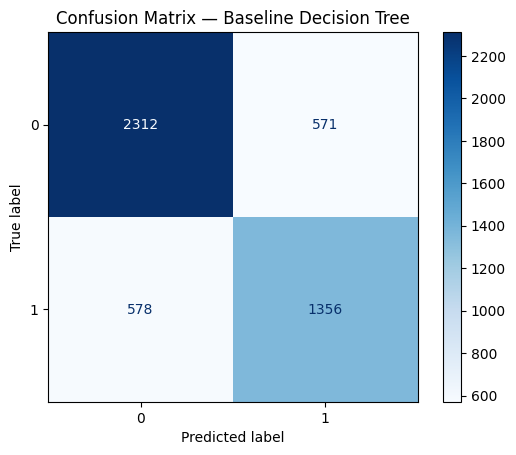

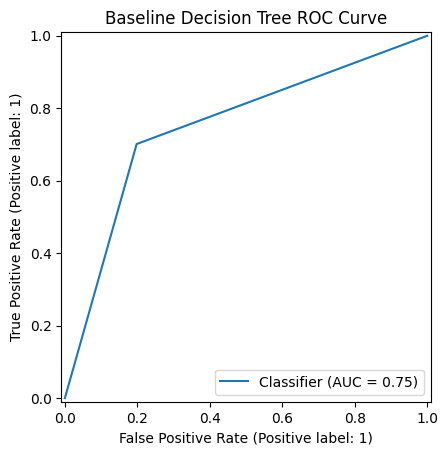

In [ ]:
baseline_dt = DecisionTreeClassifier(random_state=42)
baseline_dt.fit(X_train, y_train)

y_pred = baseline_dt.predict(X_test)
y_prob = baseline_dt.predict_proba(X_test)[:, 1]

evaluate_model(y_test, y_pred, y_prob, "Baseline Decision Tree")

RocCurveDisplay.from_predictions(y_test, y_prob)
plt.title("Baseline Decision Tree ROC Curve")
plt.show()

Tune ```max_depth```



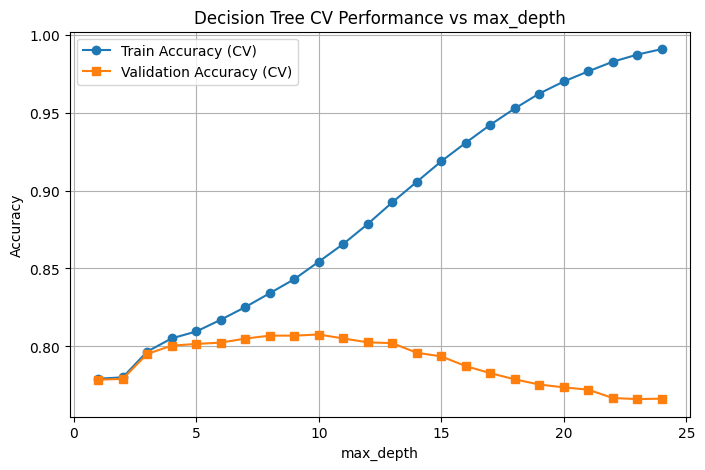

Best max_depth (CV): 10


In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

depth_values = range(1, 25)
train_acc = []
val_acc = []

for d in depth_values:
    dt = DecisionTreeClassifier(max_depth=d, random_state=42)

    fold_train_scores = []
    fold_val_scores = []

    # 5-fold CV
    for train_idx, val_idx in cv.split(X_train, y_train):
        X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
        y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]

        dt.fit(X_tr, y_tr)

        fold_train_scores.append(accuracy_score(y_tr, dt.predict(X_tr)))
        fold_val_scores.append(accuracy_score(y_val, dt.predict(X_val)))

    # Mean CV scores
    train_acc.append(np.mean(fold_train_scores))
    val_acc.append(np.mean(fold_val_scores))

# Plot train/test accuracy for max_depth
plt.figure(figsize=(8,5))
plt.plot(depth_values, train_acc, marker='o', label='Train Accuracy (CV)')
plt.plot(depth_values, val_acc,  marker='s', label='Validation Accuracy (CV)')
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.title("Decision Tree CV Performance vs max_depth")
plt.grid(True)
plt.legend()
plt.show()

# Choose the best depth
best_depth = depth_values[val_acc.index(max(val_acc))]
print("Best max_depth (CV):", best_depth)



Tune ```min_samples_split```

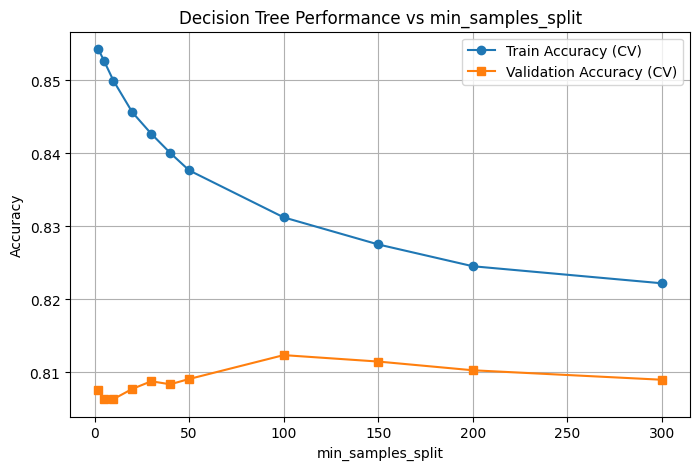

Best min_samples_split: 100


In [ ]:
split_values = [2, 5, 10, 20, 30, 40, 50, 100, 150, 200, 300]
split_train_acc = []
split_val_acc = []

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for s in split_values:
    dt = DecisionTreeClassifier(
        max_depth=best_depth,           # already tuned
        min_samples_split=s,
        random_state=42
    )

    fold_train_scores = []
    fold_val_scores = []

    # 5-fold cross validation
    for train_idx, val_idx in cv.split(X_train, y_train):
        X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
        y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]

        dt.fit(X_tr, y_tr)

        fold_train_scores.append(accuracy_score(y_tr, dt.predict(X_tr)))
        fold_val_scores.append(accuracy_score(y_val, dt.predict(X_val)))

    split_train_acc.append(np.mean(fold_train_scores))
    split_val_acc.append(np.mean(fold_val_scores))

# Plot train/test accuracy
plt.figure(figsize=(8,5))
plt.plot(split_values, split_train_acc, marker='o', label='Train Accuracy (CV)')
plt.plot(split_values, split_val_acc,  marker='s', label='Validation Accuracy (CV)')
plt.xlabel("min_samples_split")
plt.ylabel("Accuracy")
plt.title("Decision Tree Performance vs min_samples_split")
plt.grid(True)
plt.legend()
plt.show()

# Pick the best split
best_split = split_values[np.argmax(split_val_acc)]
print("Best min_samples_split:", best_split)


Tune ```min_samples_leaf```

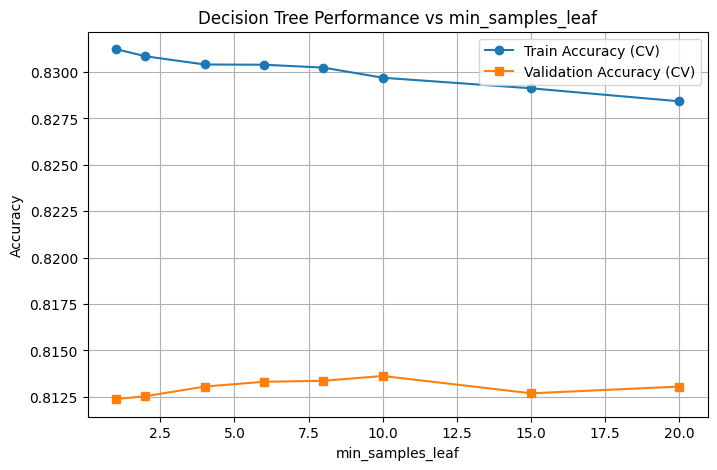

Best min_samples_leaf: 10


In [ ]:
leaf_values = [1, 2, 4, 6, 8, 10, 15, 20]
leaf_train_acc = []
leaf_val_acc = []

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for leaf in leaf_values:
    dt = DecisionTreeClassifier(
        max_depth=best_depth,
        min_samples_split=best_split,
        min_samples_leaf=leaf,
        random_state=42
    )

    fold_train_scores = []
    fold_val_scores = []

    for train_idx, val_idx in cv.split(X_train, y_train):
        X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
        y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]

        dt.fit(X_tr, y_tr)
        fold_train_scores.append(accuracy_score(y_tr, dt.predict(X_tr)))
        fold_val_scores.append(accuracy_score(y_val, dt.predict(X_val)))

    leaf_train_acc.append(np.mean(fold_train_scores))
    leaf_val_acc.append(np.mean(fold_val_scores))

# Plot train/test accuracy
plt.figure(figsize=(8,5))
plt.plot(leaf_values, leaf_train_acc, marker='o', label='Train Accuracy (CV)')
plt.plot(leaf_values, leaf_val_acc,  marker='s', label='Validation Accuracy (CV)')
plt.xlabel("min_samples_leaf")
plt.ylabel("Accuracy")
plt.title("Decision Tree Performance vs min_samples_leaf")
plt.grid(True)
plt.legend()
plt.show()

# Select the best leaf value
best_leaf = leaf_values[np.argmax(leaf_val_acc)]
print("Best min_samples_leaf:", best_leaf)

Tune ```max_leaf_nodes```

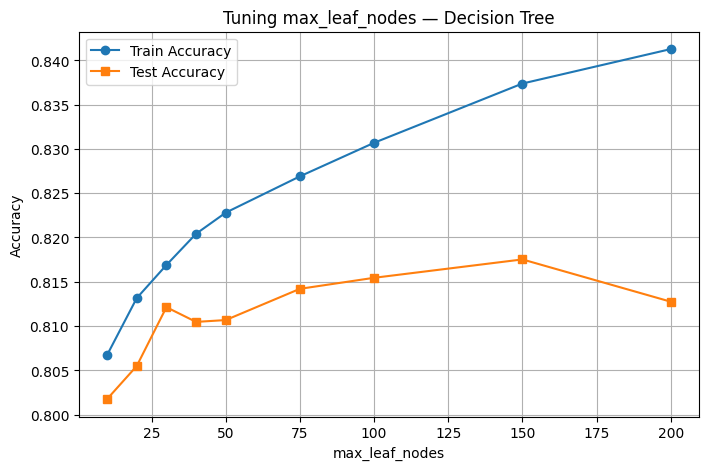

Best max_leaf_nodes: 150


In [ ]:
leaf_node_values = [None, 10, 20, 30, 40, 50, 75, 100, 150, 200]
train_acc = []
test_acc = []

for nodes in leaf_node_values:
    dt = DecisionTreeClassifier(
        max_depth=best_depth,
        min_samples_split=best_split,
        min_impurity_decrease=best_impurity,
        ccp_alpha=best_alpha,
        min_samples_leaf=best_leaf,
        max_leaf_nodes=nodes,
        random_state=42
    )
    dt.fit(X_train, y_train)

    train_acc.append(accuracy_score(y_train, dt.predict(X_train)))
    test_acc.append(accuracy_score(y_test, dt.predict(X_test)))

plt.figure(figsize=(8,5))
plt.plot(leaf_node_values, train_acc, marker='o', label='Train Accuracy')
plt.plot(leaf_node_values, test_acc, marker='s', label='Test Accuracy')
plt.xlabel("max_leaf_nodes")
plt.ylabel("Accuracy")
plt.title("Tuning max_leaf_nodes — Decision Tree")
plt.grid(True)
plt.legend()
plt.show()

best_leaf_nodes = leaf_node_values[test_acc.index(max(test_acc))]
print("Best max_leaf_nodes:", best_leaf_nodes)


Final Best Decision Tree


===== Best Tuned Decision Tree =====
Accuracy:  0.8146
Precision: 0.7555
Recall:    0.7958
F1 Score:  0.7751
AUC:       0.8940

Confusion Matrix:
[[2385  498]
 [ 395 1539]]

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.83      0.84      2883
           1       0.76      0.80      0.78      1934

    accuracy                           0.81      4817
   macro avg       0.81      0.81      0.81      4817
weighted avg       0.82      0.81      0.82      4817



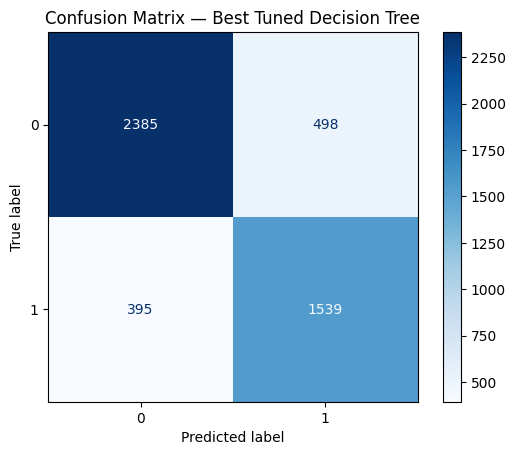

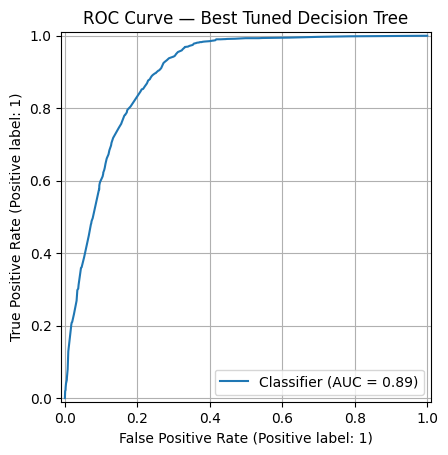

In [ ]:
best_dt = DecisionTreeClassifier(
    max_depth=best_depth,
    min_samples_split=best_split,
    min_samples_leaf=best_leaf,
    random_state=42
)

best_dt.fit(X_train, y_train)

y_pred_dt = best_dt.predict(X_test)
y_prob_dt = best_dt.predict_proba(X_test)[:, 1]

evaluate_model(y_test, y_pred_dt, y_prob_dt, "Best Tuned Decision Tree")

RocCurveDisplay.from_predictions(y_test, y_prob_dt)
plt.title("ROC Curve — Best Tuned Decision Tree")
plt.grid(True)
plt.show()


Feature Selection (SelectKBest)

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

max_features = X_train.shape[1]
fs_val_scores_dt = []

baseline_dt = DecisionTreeClassifier(random_state=42)   # <-- baseline model

for f in range(1, max_features + 1):
    selector = SelectKBest(f_classif, k=f)
    X_train_fs_f = selector.fit_transform(X_train, y_train)
    X_train_fs_f = pd.DataFrame(X_train_fs_f)

    fold_val_scores = []

    for train_idx, val_idx in cv.split(X_train_fs_f, y_train):
        X_tr, X_val = X_train_fs_f.iloc[train_idx], X_train_fs_f.iloc[val_idx]
        y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]

        baseline_dt.fit(X_tr, y_tr)
        fold_val_scores.append(accuracy_score(y_val, baseline_dt.predict(X_val)))

    fs_val_scores_dt.append(np.mean(fold_val_scores))

# Best number of features from FS
best_k_features_dt = np.argmax(fs_val_scores_dt) + 1
print("Best number of features for Decision Tree:", best_k_features_dt)

Best number of features for Decision Tree: 1


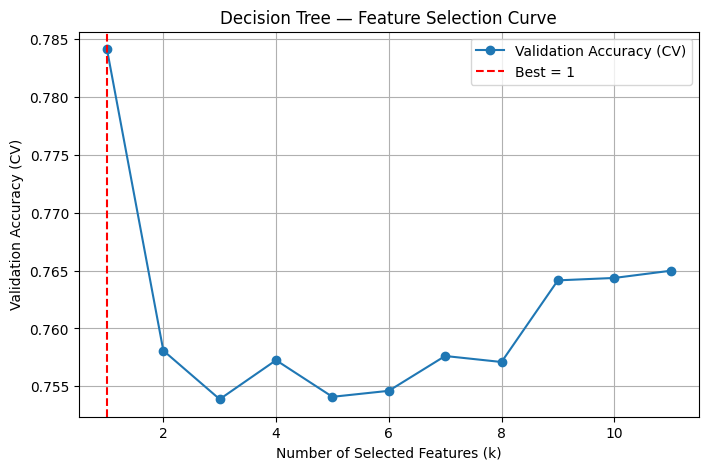

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(range(1, max_features + 1), fs_val_scores_dt,
         marker='o', label='Validation Accuracy (CV)')
plt.axvline(best_k_features_dt, color='red', linestyle='--',
            label=f'Best = {best_k_features_dt}')
plt.xlabel("Number of Selected Features (k)")
plt.ylabel("Validation Accuracy (CV)")
plt.title("Decision Tree — Feature Selection Curve")
plt.grid(True)
plt.legend()
plt.show()


In [ ]:
# Apply feature selection using the chosen k
fs_selector_dt = SelectKBest(f_classif, k=best_k_features_dt)
X_train_fs = fs_selector_dt.fit_transform(X_train, y_train)
X_test_fs  = fs_selector_dt.transform(X_test)

X_train_fs = pd.DataFrame(X_train_fs, index=X_train.index)
X_test_fs  = pd.DataFrame(X_test_fs,  index=X_test.index)


Tune hyperparameters individually using the FS-reduced dataset

Tune `max_depth`

Best max_depth after FS: 6


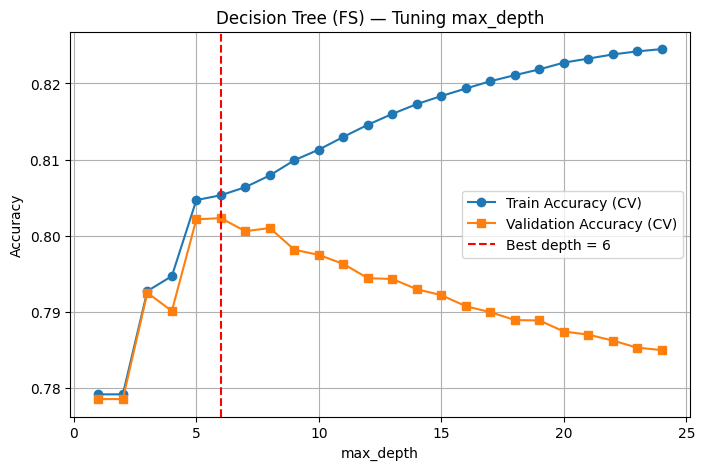

In [ ]:
X_train_fs = fs_selector_dt.fit_transform(X_train, y_train)
X_test_fs  = fs_selector_dt.transform(X_test)
X_train_fs = pd.DataFrame(X_train_fs)

depth_values = range(1, 25)
depth_train_acc_fs = []
depth_val_acc_fs = []

for d in depth_values:
    dt = DecisionTreeClassifier(max_depth=d, random_state=42)

    fold_train = []
    fold_val = []

    for train_idx, val_idx in cv.split(X_train_fs, y_train):
        X_tr, X_val = X_train_fs.iloc[train_idx], X_train_fs.iloc[val_idx]
        y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]

        dt.fit(X_tr, y_tr)
        fold_train.append(accuracy_score(y_tr, dt.predict(X_tr)))
        fold_val.append(accuracy_score(y_val, dt.predict(X_val)))

    depth_train_acc_fs.append(np.mean(fold_train))
    depth_val_acc_fs.append(np.mean(fold_val))

best_depth_FS = depth_values[np.argmax(depth_val_acc_fs)]
print("Best max_depth after FS:", best_depth_FS)

# Plot train/test accuracy for max_depth
plt.figure(figsize=(8,5))
plt.plot(depth_values, depth_train_acc_fs, marker='o', label='Train Accuracy (CV)')
plt.plot(depth_values, depth_val_acc_fs,  marker='s', label='Validation Accuracy (CV)')
plt.axvline(best_depth_FS, color='red', linestyle='--', label=f"Best depth = {best_depth_FS}")
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.title("Decision Tree (FS) — Tuning max_depth")
plt.grid(True)
plt.legend()
plt.show()



Tune `min_samples_split`

Best min_samples_split after FS: 300


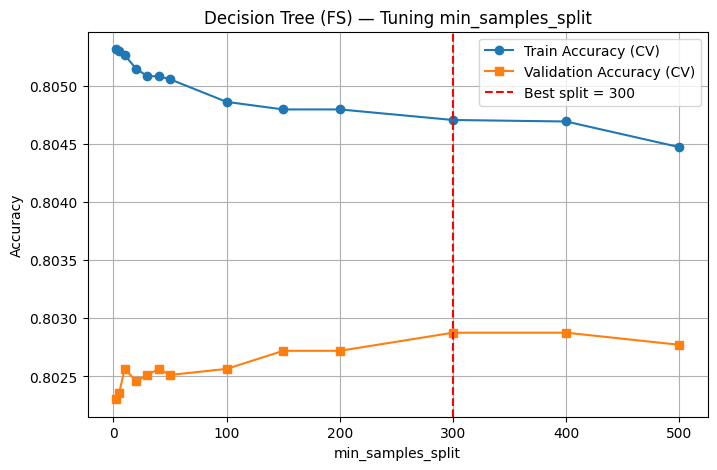

In [ ]:
split_values = [2, 5, 10, 20, 30, 40, 50, 100, 150, 200, 300, 400, 500]
split_train_acc_fs = []
split_val_acc_fs = []

for s in split_values:
    dt = DecisionTreeClassifier(
        max_depth=best_depth_FS,
        min_samples_split=s,
        random_state=42
    )

    fold_train = []
    fold_val = []

    for train_idx, val_idx in cv.split(X_train_fs, y_train):
        X_tr, X_val = X_train_fs.iloc[train_idx], X_train_fs.iloc[val_idx]
        y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]

        dt.fit(X_tr, y_tr)
        fold_train.append(accuracy_score(y_tr, dt.predict(X_tr)))
        fold_val.append(accuracy_score(y_val, dt.predict(X_val)))

    split_train_acc_fs.append(np.mean(fold_train))
    split_val_acc_fs.append(np.mean(fold_val))

best_split_FS = split_values[np.argmax(split_val_acc_fs)]
print("Best min_samples_split after FS:", best_split_FS)

# Plot train/test accuracy
plt.figure(figsize=(8,5))
plt.plot(split_values, split_train_acc_fs, marker='o', label='Train Accuracy (CV)')
plt.plot(split_values, split_val_acc_fs,  marker='s', label='Validation Accuracy (CV)')
plt.axvline(best_split_FS, color='red', linestyle='--', label=f"Best split = {best_split_FS}")
plt.xlabel("min_samples_split")
plt.ylabel("Accuracy")
plt.title("Decision Tree (FS) — Tuning min_samples_split")
plt.grid(True)
plt.legend()
plt.show()


tune `min_samples_leaf`

Best min_samples_leaf after FS: 25


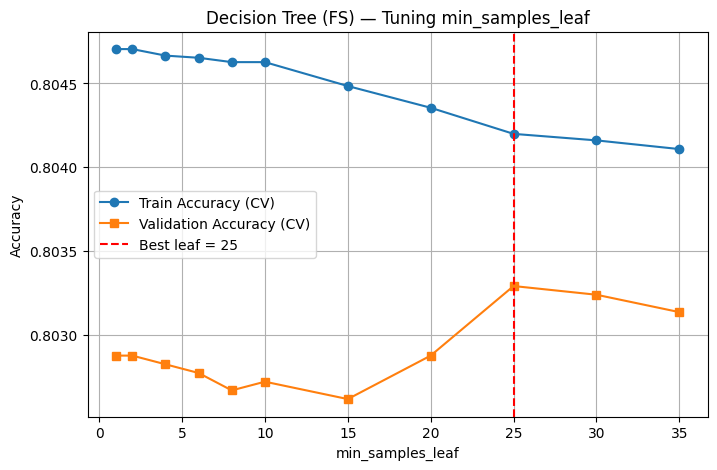

In [ ]:
leaf_values = [1, 2, 4, 6, 8, 10, 15, 20, 25, 30, 35]
leaf_train_acc_fs = []
leaf_val_acc_fs = []

for leaf in leaf_values:
    dt = DecisionTreeClassifier(
        max_depth=best_depth_FS,
        min_samples_split=best_split_FS,
        min_samples_leaf=leaf,
        random_state=42
    )

    fold_train = []
    fold_val = []

    for train_idx, val_idx in cv.split(X_train_fs, y_train):
        X_tr, X_val = X_train_fs.iloc[train_idx], X_train_fs.iloc[val_idx]
        y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]

        dt.fit(X_tr, y_tr)
        fold_train.append(accuracy_score(y_tr, dt.predict(X_tr)))
        fold_val.append(accuracy_score(y_val, dt.predict(X_val)))

    leaf_train_acc_fs.append(np.mean(fold_train))
    leaf_val_acc_fs.append(np.mean(fold_val))

best_leaf_FS = leaf_values[np.argmax(leaf_val_acc_fs)]
print("Best min_samples_leaf after FS:", best_leaf_FS)

# Plot train/test accuracy
plt.figure(figsize=(8,5))
plt.plot(leaf_values, leaf_train_acc_fs, marker='o', label='Train Accuracy (CV)')
plt.plot(leaf_values, leaf_val_acc_fs,  marker='s', label='Validation Accuracy (CV)')
plt.axvline(best_leaf_FS, color='red', linestyle='--', label=f"Best leaf = {best_leaf_FS}")
plt.xlabel("min_samples_leaf")
plt.ylabel("Accuracy")
plt.title("Decision Tree (FS) — Tuning min_samples_leaf")
plt.grid(True)
plt.legend()
plt.show()

Final DT model after feature selection


===== Final Decision Tree + Feature Selection =====
Accuracy:  0.8024
Precision: 0.7109
Recall:    0.8557
F1 Score:  0.7766
AUC:       0.8737

Confusion Matrix:
[[2210  673]
 [ 279 1655]]

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.77      0.82      2883
           1       0.71      0.86      0.78      1934

    accuracy                           0.80      4817
   macro avg       0.80      0.81      0.80      4817
weighted avg       0.82      0.80      0.80      4817



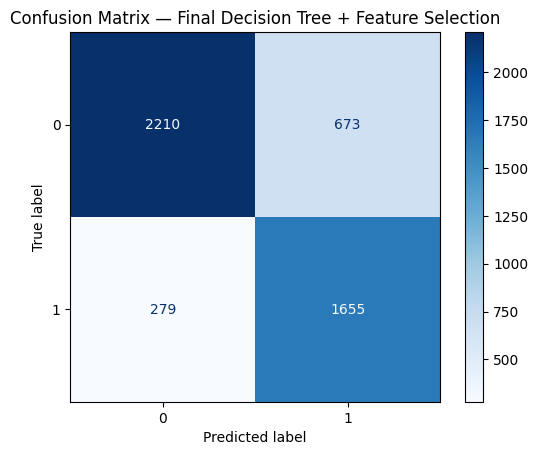

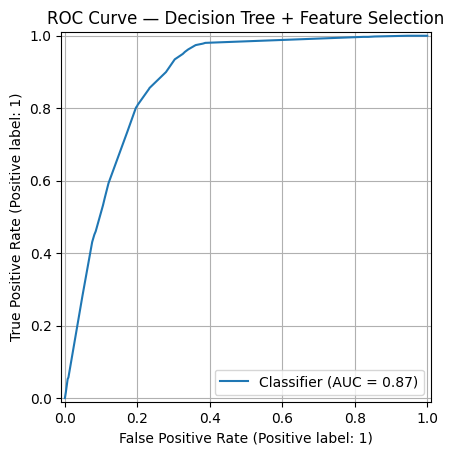

In [ ]:
best_dt_fs = DecisionTreeClassifier(
    max_depth=best_depth_FS,
    min_samples_split=best_split_FS,
    min_samples_leaf=best_leaf_FS,
    random_state=42
)

best_dt_fs.fit(X_train_fs, y_train)

y_pred_dt_fs = best_dt_fs.predict(X_test_fs)
y_prob_dt_fs = best_dt_fs.predict_proba(X_test_fs)[:, 1]

evaluate_model(y_test, y_pred_dt_fs, y_prob_dt_fs,
               name="Final Decision Tree + Feature Selection")

RocCurveDisplay.from_predictions(y_test, y_prob_dt_fs)
plt.title("ROC Curve — Decision Tree + Feature Selection")
plt.grid(True)
plt.show()


PCA (>= 90% variance) + Decision Tree

Number of PCA components for ≥90% variance: 6


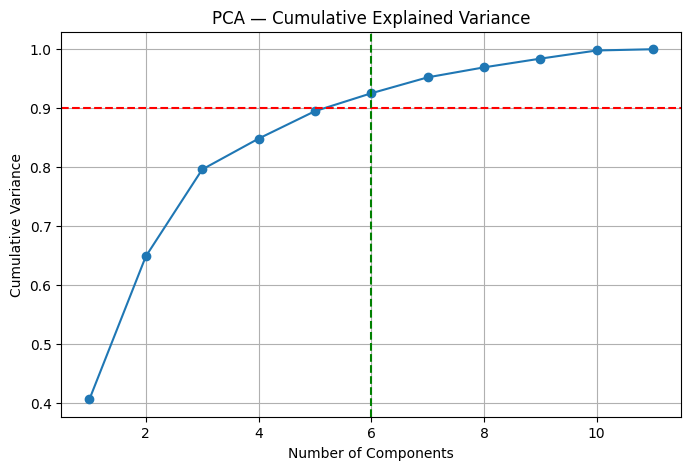

In [ ]:
pca_full = PCA().fit(X_train)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)

# Components for ≥90% variance
n_components_90 = np.argmax(cum_var >= 0.90) + 1
print("Number of PCA components for ≥90% variance:", n_components_90)

# Plot cumulative variance
plt.figure(figsize=(8,5))
plt.plot(range(1, len(cum_var)+1), cum_var, marker='o')
plt.axhline(0.90, color='red', linestyle='--')
plt.axvline(n_components_90, color='green', linestyle='--')
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Variance")
plt.title("PCA — Cumulative Explained Variance")
plt.grid(True)
plt.show()


Tune `max_depth`

Best max_depth (PCA): 8


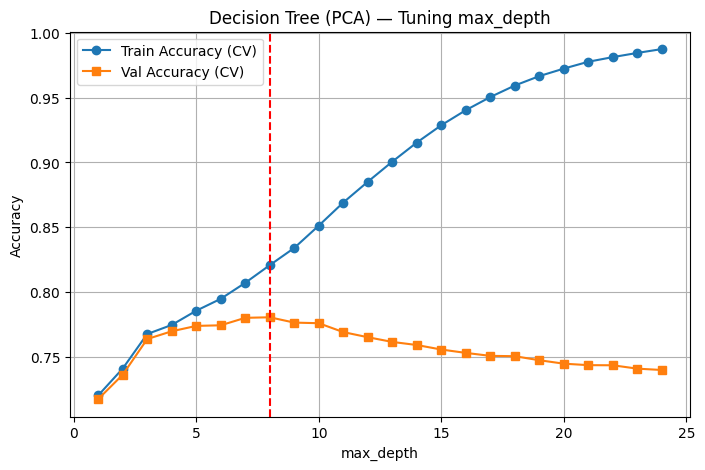

In [ ]:
depth_values = range(1, 25)
depth_train_acc_pca = []
depth_val_acc_pca = []

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for d in depth_values:
    pca_d = PCA(n_components=n_components_90)
    X_train_pca_d = pca_d.fit_transform(X_train)
    X_train_pca_d = pd.DataFrame(X_train_pca_d)

    dt = DecisionTreeClassifier(max_depth=d, random_state=42)

    fold_train, fold_val = [], []

    for train_idx, val_idx in cv.split(X_train_pca_d, y_train):
        X_tr, X_val = X_train_pca_d.iloc[train_idx], X_train_pca_d.iloc[val_idx]
        y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]

        dt.fit(X_tr, y_tr)
        fold_train.append(accuracy_score(y_tr, dt.predict(X_tr)))
        fold_val.append(accuracy_score(y_val, dt.predict(X_val)))

    depth_train_acc_pca.append(np.mean(fold_train))
    depth_val_acc_pca.append(np.mean(fold_val))

best_depth_pca = depth_values[np.argmax(depth_val_acc_pca)]
print("Best max_depth (PCA):", best_depth_pca)

# Plot train/test accuracy for max_depth
plt.figure(figsize=(8,5))
plt.plot(depth_values, depth_train_acc_pca, marker='o', label='Train Accuracy (CV)')
plt.plot(depth_values, depth_val_acc_pca,  marker='s', label='Val Accuracy (CV)')
plt.axvline(best_depth_pca, color='red', linestyle='--')
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.title("Decision Tree (PCA) — Tuning max_depth")
plt.grid(True)
plt.legend()
plt.show()


tune `min_samples_split`

Best min_samples_split (PCA): 120


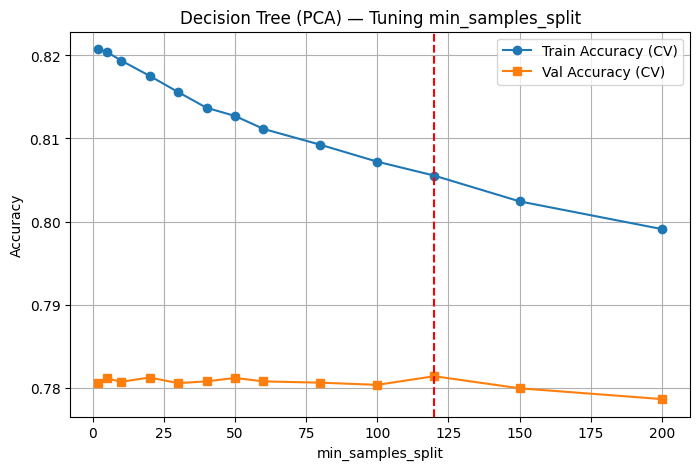

In [ ]:
split_values = [2, 5, 10, 20, 30, 40, 50, 60, 80, 100, 120, 150, 200]
split_train_acc_pca = []
split_val_acc_pca = []

for s in split_values:
    pca_s = PCA(n_components=n_components_90)
    X_train_pca_s = pca_s.fit_transform(X_train)
    X_train_pca_s = pd.DataFrame(X_train_pca_s)

    dt = DecisionTreeClassifier(
        max_depth=best_depth_pca,
        min_samples_split=s,
        random_state=42
    )

    fold_train, fold_val = [], []

    for train_idx, val_idx in cv.split(X_train_pca_s, y_train):
        X_tr, X_val = X_train_pca_s.iloc[train_idx], X_train_pca_s.iloc[val_idx]
        y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]

        dt.fit(X_tr, y_tr)
        fold_train.append(accuracy_score(y_tr, dt.predict(X_tr)))
        fold_val.append(accuracy_score(y_val, dt.predict(X_val)))

    split_train_acc_pca.append(np.mean(fold_train))
    split_val_acc_pca.append(np.mean(fold_val))

best_split_pca = split_values[np.argmax(split_val_acc_pca)]
print("Best min_samples_split (PCA):", best_split_pca)

# Plot train/test accuracy
plt.figure(figsize=(8,5))
plt.plot(split_values, split_train_acc_pca, marker='o', label='Train Accuracy (CV)')
plt.plot(split_values, split_val_acc_pca,  marker='s', label='Val Accuracy (CV)')
plt.axvline(best_split_pca, color='red', linestyle='--')
plt.xlabel("min_samples_split")
plt.ylabel("Accuracy")
plt.title("Decision Tree (PCA) — Tuning min_samples_split")
plt.grid(True)
plt.legend()
plt.show()

tune `min_samples_leaf`

Best min_samples_leaf (PCA): 6


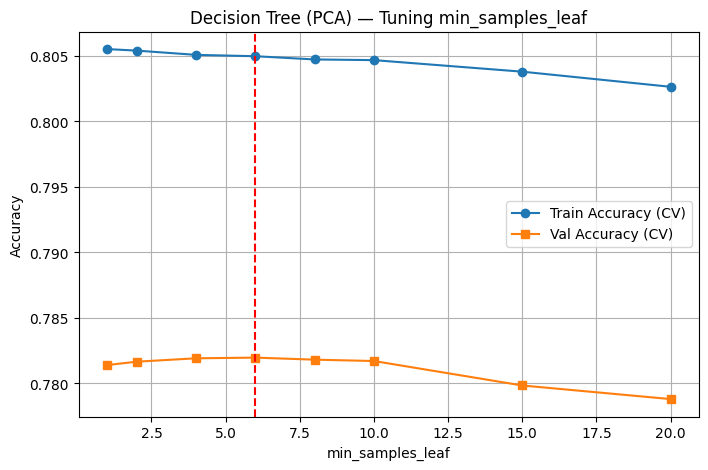

In [ ]:
leaf_values = [1, 2, 4, 6, 8, 10, 15, 20]
leaf_train_acc_pca = []
leaf_val_acc_pca = []

for leaf in leaf_values:
    pca_leaf = PCA(n_components=n_components_90)
    X_train_pca_leaf = pca_leaf.fit_transform(X_train)
    X_train_pca_leaf = pd.DataFrame(X_train_pca_leaf)

    dt = DecisionTreeClassifier(
        max_depth=best_depth_pca,
        min_samples_split=best_split_pca,
        min_samples_leaf=leaf,
        random_state=42
    )

    fold_train, fold_val = [], []

    for train_idx, val_idx in cv.split(X_train_pca_leaf, y_train):
        X_tr, X_val = X_train_pca_leaf.iloc[train_idx], X_train_pca_leaf.iloc[val_idx]
        y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]

        dt.fit(X_tr, y_tr)
        fold_train.append(accuracy_score(y_tr, dt.predict(X_tr)))
        fold_val.append(accuracy_score(y_val, dt.predict(X_val)))

    leaf_train_acc_pca.append(np.mean(fold_train))
    leaf_val_acc_pca.append(np.mean(fold_val))

best_leaf_pca = leaf_values[np.argmax(leaf_val_acc_pca)]
print("Best min_samples_leaf (PCA):", best_leaf_pca)

# Plot train/test accuracy
plt.figure(figsize=(8,5))
plt.plot(leaf_values, leaf_train_acc_pca, marker='o', label='Train Accuracy (CV)')
plt.plot(leaf_values, leaf_val_acc_pca,  marker='s', label='Val Accuracy (CV)')
plt.axvline(best_leaf_pca, color='red', linestyle='--')
plt.xlabel("min_samples_leaf")
plt.ylabel("Accuracy")
plt.title("Decision Tree (PCA) — Tuning min_samples_leaf")
plt.grid(True)
plt.legend()
plt.show()

Final PCA Decision Tree Model


===== Decision Tree + PCA =====
Accuracy:  0.7833
Precision: 0.6957
Recall:    0.8180
F1 Score:  0.7519
AUC:       0.8552

Confusion Matrix:
[[2191  692]
 [ 352 1582]]

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.76      0.81      2883
           1       0.70      0.82      0.75      1934

    accuracy                           0.78      4817
   macro avg       0.78      0.79      0.78      4817
weighted avg       0.79      0.78      0.79      4817



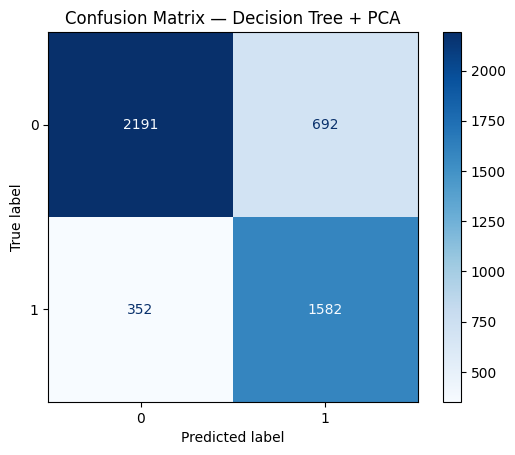

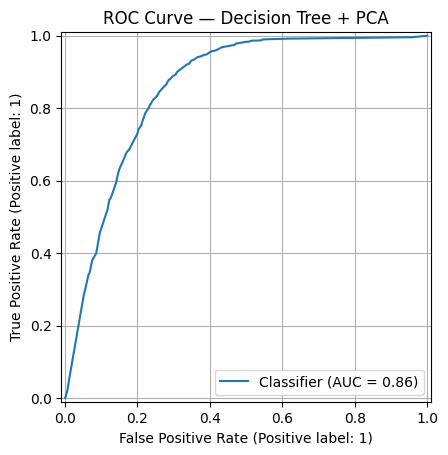

In [ ]:
best_pca = PCA(n_components=n_components_90).fit(X_train)
X_train_pca_final = best_pca.transform(X_train)
X_test_pca_final  = best_pca.transform(X_test)

best_dt_pca = DecisionTreeClassifier(
    max_depth=best_depth_pca,
    min_samples_split=best_split_pca,
    min_samples_leaf=best_leaf_pca,
    random_state=42
)

best_dt_pca.fit(X_train_pca_final, y_train)

y_pred_pca_dt = best_dt_pca.predict(X_test_pca_final)
y_prob_pca_dt = best_dt_pca.predict_proba(X_test_pca_final)[:, 1]

evaluate_model(y_test, y_pred_pca_dt, y_prob_pca_dt,
               name="Decision Tree + PCA")

RocCurveDisplay.from_predictions(y_test, y_prob_pca_dt)
plt.title("ROC Curve — Decision Tree + PCA")
plt.grid(True)
plt.show()


##Summary:
The Decision Tree model was tested in stages to understand how tuning and dimensionality reduction affect accuracy. A baseline tree was trained first to provide a reference point. The three key hyperparameters were then tuned individually using five-fold cross-validation, which reduced overfitting and produced a more reliable model. Feature Selection was applied using a baseline tree to identify how many features gave the highest validation accuracy. The model was rebuilt on this reduced feature set and tuned again, which improved performance because irrelevant features were removed. PCA was then applied as an alternative approach. After selecting the number of components that captured at least ninety percent of the variance, the same tuning process was repeated. PCA improved accuracy over the baseline but did not outperform Feature Selection because it preserves variance rather than features that are most useful for classification. Overall, tuning and dimensionality reduction improved the Decision Tree model, and Feature Selection produced the strongest results.

#3. Naive Bayes (Mohamed Zein)

imports

In [ ]:
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB

Baseline Naive Bayes models


===== GaussianNB Baseline =====
Accuracy:  0.7588
Precision: 0.6643
Recall:    0.8071
F1 Score:  0.7288
AUC:       0.8346

Confusion Matrix:
[[2094  789]
 [ 373 1561]]

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.73      0.78      2883
           1       0.66      0.81      0.73      1934

    accuracy                           0.76      4817
   macro avg       0.76      0.77      0.76      4817
weighted avg       0.77      0.76      0.76      4817



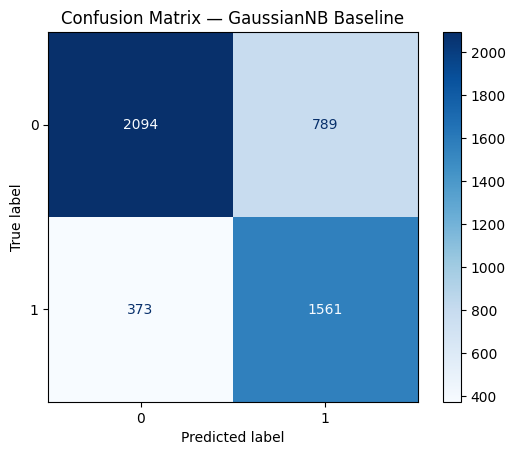


===== BernoulliNB Baseline =====
Accuracy:  0.7856
Precision: 0.6853
Recall:    0.8614
F1 Score:  0.7633
AUC:       0.8426

Confusion Matrix:
[[2118  765]
 [ 268 1666]]

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.73      0.80      2883
           1       0.69      0.86      0.76      1934

    accuracy                           0.79      4817
   macro avg       0.79      0.80      0.78      4817
weighted avg       0.81      0.79      0.79      4817



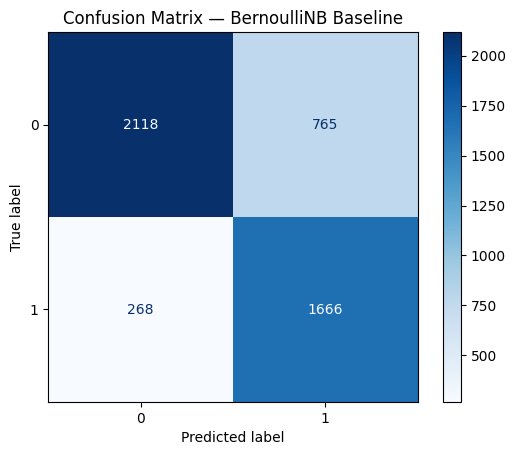

In [ ]:
# Gaussian NB
gnb = GaussianNB()
gnb.fit(X_train, y_train)

y_pred_g = gnb.predict(X_test)
y_prob_g = gnb.predict_proba(X_test)[:, 1]

evaluate_model(y_test, y_pred_g, y_prob_g, "GaussianNB Baseline")

# Bernoulli NB
bnb = BernoulliNB()
bnb.fit(X_train, y_train)

y_pred_b = bnb.predict(X_test)
y_prob_b = bnb.predict_proba(X_test)[:, 1]

evaluate_model(y_test, y_pred_b, y_prob_b, "BernoulliNB Baseline")

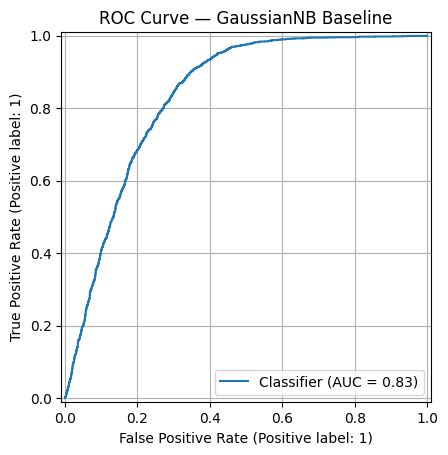

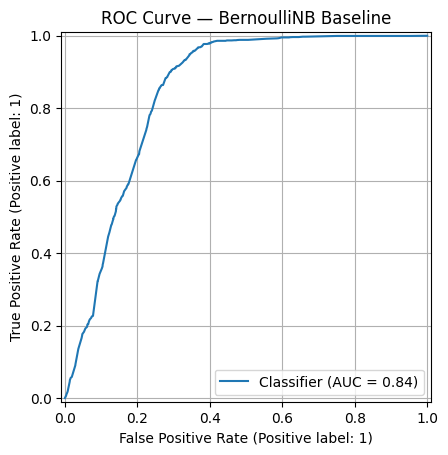

In [ ]:
# ROC Curves for both baselines
RocCurveDisplay.from_predictions(y_test, y_prob_g)
plt.title("ROC Curve — GaussianNB Baseline")
plt.grid(True)
plt.show()

RocCurveDisplay.from_predictions(y_test, y_prob_b)
plt.title("ROC Curve — BernoulliNB Baseline")
plt.grid(True)
plt.show()


GaussianNB feature selection

Best number of features for GaussianNB: 3


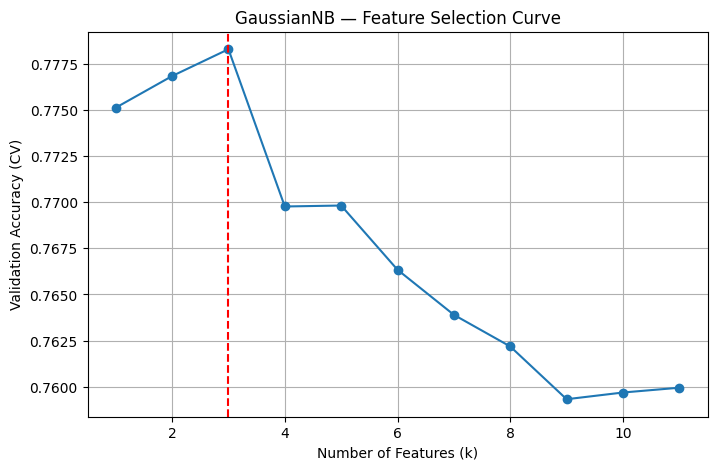

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

max_features = X_train.shape[1]
fs_val_scores_gnb = []

for k in range(1, max_features + 1):

    selector = SelectKBest(f_classif, k=k)
    X_train_fs = selector.fit_transform(X_train, y_train)
    X_train_fs = pd.DataFrame(X_train_fs)

    gnb = GaussianNB()

    fold_val_scores = []

    for train_idx, val_idx in cv.split(X_train_fs, y_train):
        X_tr, X_val = X_train_fs.iloc[train_idx], X_train_fs.iloc[val_idx]
        y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]

        gnb.fit(X_tr, y_tr)
        fold_val_scores.append(accuracy_score(y_val, gnb.predict(X_val)))

    fs_val_scores_gnb.append(np.mean(fold_val_scores))

best_k_gnb = fs_val_scores_gnb.index(max(fs_val_scores_gnb)) + 1
print("Best number of features for GaussianNB:", best_k_gnb)

# Plot feature selection curve
plt.figure(figsize=(8,5))
plt.plot(range(1, max_features + 1), fs_val_scores_gnb, marker='o')
plt.axvline(best_k_gnb, color='red', linestyle='--')
plt.title("GaussianNB — Feature Selection Curve")
plt.xlabel("Number of Features (k)")
plt.ylabel("Validation Accuracy (CV)")
plt.grid(True)
plt.show()


===== GaussianNB + Feature Selection =====
Accuracy:  0.7772
Precision: 0.6720
Recall:    0.8697
F1 Score:  0.7582
AUC:       0.8551

Confusion Matrix:
[[2062  821]
 [ 252 1682]]

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.72      0.79      2883
           1       0.67      0.87      0.76      1934

    accuracy                           0.78      4817
   macro avg       0.78      0.79      0.78      4817
weighted avg       0.80      0.78      0.78      4817



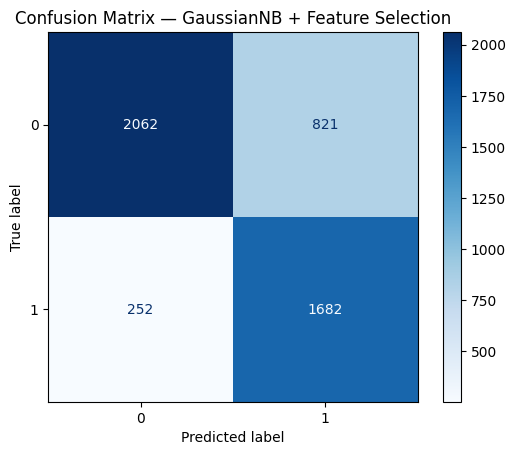

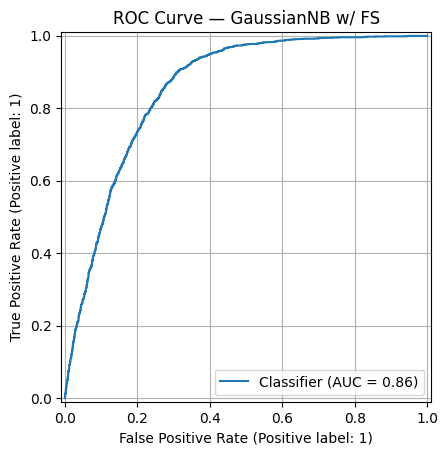

In [ ]:
# Train GaussianNB with the best k features
selector_gnb = SelectKBest(f_classif, k=best_k_gnb)
X_train_fs_gnb = selector_gnb.fit_transform(X_train, y_train)
X_test_fs_gnb  = selector_gnb.transform(X_test)

gnb_fs = GaussianNB()
gnb_fs.fit(X_train_fs_gnb, y_train)

y_pred_g_fs = gnb_fs.predict(X_test_fs_gnb)
y_prob_g_fs = gnb_fs.predict_proba(X_test_fs_gnb)[:, 1]

evaluate_model(y_test, y_pred_g_fs, y_prob_g_fs, "GaussianNB + Feature Selection")

RocCurveDisplay.from_predictions(y_test, y_prob_g_fs)
plt.title("ROC Curve — GaussianNB w/ FS")
plt.grid(True)
plt.show()

BernoulliNB feature selection

Best number of features for BernoulliNB: 2


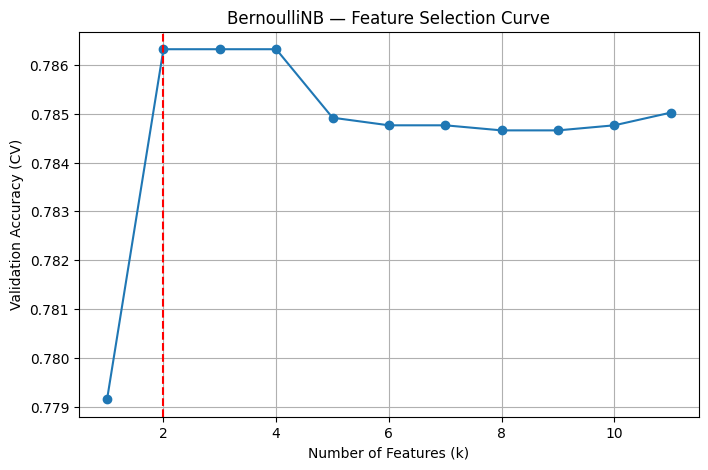

In [ ]:
fs_val_scores_bnb = []

for k in range(1, max_features + 1):

    selector = SelectKBest(f_classif, k=k)
    X_train_fs = selector.fit_transform(X_train, y_train)
    X_train_fs = pd.DataFrame(X_train_fs)

    bnb = BernoulliNB()

    fold_val_scores = []

    for train_idx, val_idx in cv.split(X_train_fs, y_train):
        X_tr, X_val = X_train_fs.iloc[train_idx], X_train_fs.iloc[val_idx]
        y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]

        bnb.fit(X_tr, y_tr)
        fold_val_scores.append(accuracy_score(y_val, bnb.predict(X_val)))

    fs_val_scores_bnb.append(np.mean(fold_val_scores))

best_k_bnb = fs_val_scores_bnb.index(max(fs_val_scores_bnb)) + 1
print("Best number of features for BernoulliNB:", best_k_bnb)

# Plot FS curve
plt.figure(figsize=(8,5))
plt.plot(range(1, max_features + 1), fs_val_scores_bnb, marker='o')
plt.axvline(best_k_bnb, color='red', linestyle='--')
plt.title("BernoulliNB — Feature Selection Curve")
plt.xlabel("Number of Features (k)")
plt.ylabel("Validation Accuracy (CV)")
plt.grid(True)
plt.show()



===== BernoulliNB + Feature Selection =====
Accuracy:  0.7845
Precision: 0.6886
Recall:    0.8459
F1 Score:  0.7592
AUC:       0.8372

Confusion Matrix:
[[2143  740]
 [ 298 1636]]

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.74      0.81      2883
           1       0.69      0.85      0.76      1934

    accuracy                           0.78      4817
   macro avg       0.78      0.79      0.78      4817
weighted avg       0.80      0.78      0.79      4817



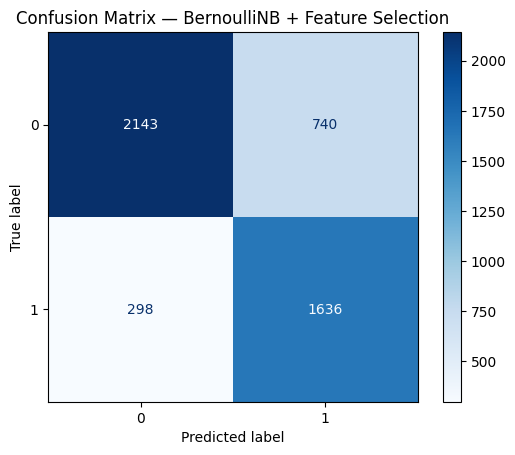

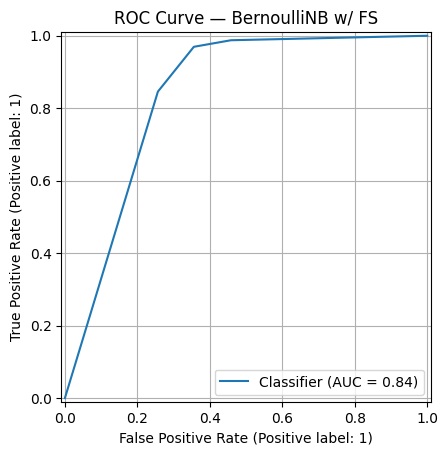

In [ ]:
# Train BernoulliNB with the best k features
selector_bnb = SelectKBest(f_classif, k=best_k_bnb)
X_train_fs_bnb = selector_bnb.fit_transform(X_train, y_train)
X_test_fs_bnb  = selector_bnb.transform(X_test)

bnb_fs = BernoulliNB()
bnb_fs.fit(X_train_fs_bnb, y_train)

y_pred_b_fs = bnb_fs.predict(X_test_fs_bnb)
y_prob_b_fs = bnb_fs.predict_proba(X_test_fs_bnb)[:, 1]

evaluate_model(y_test, y_pred_b_fs, y_prob_b_fs, "BernoulliNB + Feature Selection")

RocCurveDisplay.from_predictions(y_test, y_prob_b_fs)
plt.title("ROC Curve — BernoulliNB w/ FS")
plt.grid(True)
plt.show()

PCA (>= 90%) + Naive Bayes

PCA components for ≥90 percent variance (NB): 6


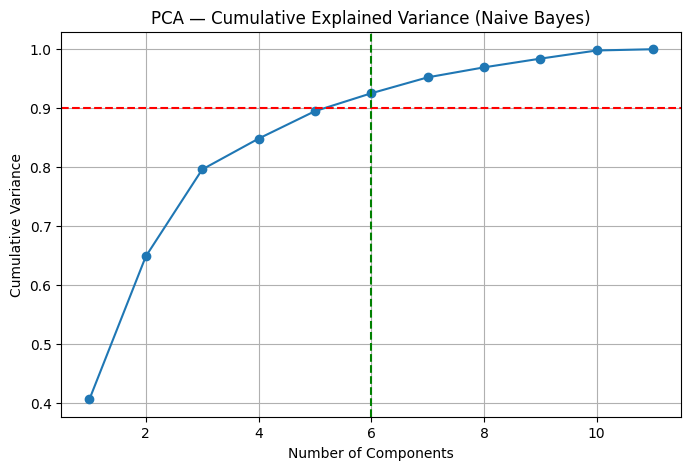


===== GaussianNB + PCA =====
Accuracy:  0.7716
Precision: 0.6901
Recall:    0.7828
F1 Score:  0.7335
AUC:       0.8521

Confusion Matrix:
[[2203  680]
 [ 420 1514]]

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.76      0.80      2883
           1       0.69      0.78      0.73      1934

    accuracy                           0.77      4817
   macro avg       0.76      0.77      0.77      4817
weighted avg       0.78      0.77      0.77      4817



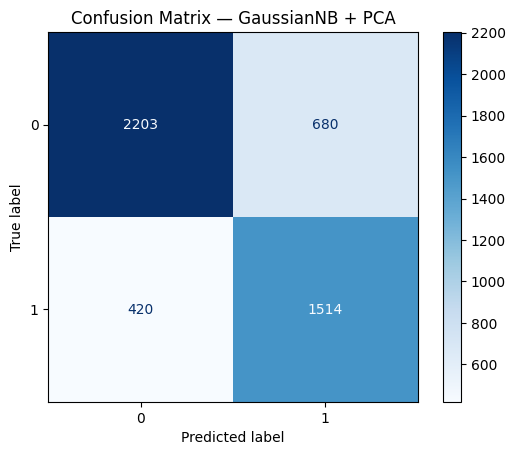

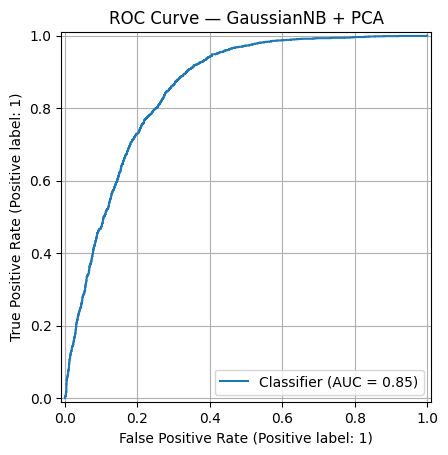


===== BernoulliNB + PCA =====
Accuracy:  0.7299
Precision: 0.6257
Recall:    0.8144
F1 Score:  0.7077
AUC:       0.7954

Confusion Matrix:
[[1941  942]
 [ 359 1575]]

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.67      0.75      2883
           1       0.63      0.81      0.71      1934

    accuracy                           0.73      4817
   macro avg       0.73      0.74      0.73      4817
weighted avg       0.76      0.73      0.73      4817



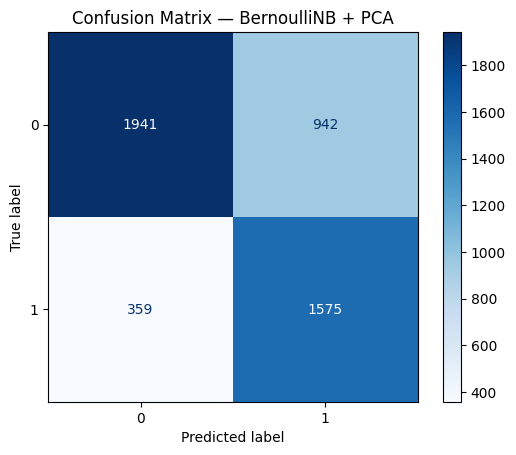

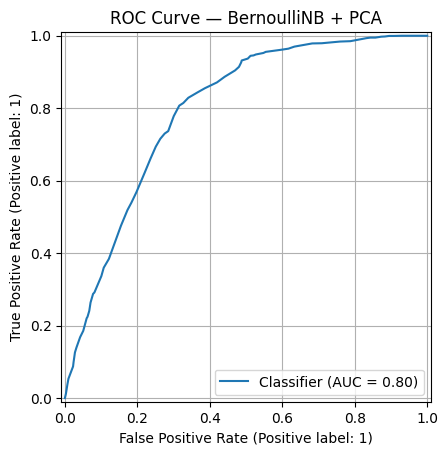

In [ ]:
# Fit PCA on training data (no scaling)
pca_full_nb = PCA().fit(X_train)
cum_var_nb = np.cumsum(pca_full_nb.explained_variance_ratio_)

# Determine number of components that explain ≥ 90 percent variance
n_components_90_nb = np.argmax(cum_var_nb >= 0.90) + 1
print("PCA components for ≥90 percent variance (NB):", n_components_90_nb)

# Plot PCA curve
plt.figure(figsize=(8,5))
plt.plot(range(1, len(cum_var_nb)+1), cum_var_nb, marker='o')
plt.axhline(0.90, color='red', linestyle='--')
plt.axvline(n_components_90_nb, color='green', linestyle='--')
plt.title("PCA — Cumulative Explained Variance (Naive Bayes)")
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Variance")
plt.grid(True)
plt.show()

pca_nb = PCA(n_components=n_components_90_nb)
X_train_pca_nb = pca_nb.fit_transform(X_train)
X_test_pca_nb  = pca_nb.transform(X_test)

# GaussianNB + PCA
gnb_pca = GaussianNB()
gnb_pca.fit(X_train_pca_nb, y_train)

y_pred_g_pca = gnb_pca.predict(X_test_pca_nb)
y_prob_g_pca = gnb_pca.predict_proba(X_test_pca_nb)[:, 1]

evaluate_model(
    y_test,
    y_pred_g_pca,
    y_prob_g_pca,
    name="GaussianNB + PCA"
)

RocCurveDisplay.from_predictions(y_test, y_prob_g_pca)
plt.title("ROC Curve — GaussianNB + PCA")
plt.grid(True)
plt.show()

# BernoulliNB + PCA
bnb_pca = BernoulliNB()
bnb_pca.fit(X_train_pca_nb, y_train)

y_pred_b_pca = bnb_pca.predict(X_test_pca_nb)
y_prob_b_pca = bnb_pca.predict_proba(X_test_pca_nb)[:, 1]

evaluate_model(
    y_test,
    y_pred_b_pca,
    y_prob_b_pca,
    name="BernoulliNB + PCA"
)

RocCurveDisplay.from_predictions(y_test, y_prob_b_pca)
plt.title("ROC Curve — BernoulliNB + PCA")
plt.grid(True)
plt.show()




---



#4. Ensemble Methods: Gradient Boosting (Rayyan Agha Alnimer)

####Note: Gradient Boosting was chosen because it consistently performs well in structured, tabular datasets like this one, where relationships between features and the target are often non-linear and involve subtle interactions. Unlike bagging-based methods such as Random Forests, Gradient Boosting builds trees sequentially, with each new tree correcting the errors of the previous ones. This allows the model to capture complex patterns with high predictive accuracy while remaining relatively robust to overfitting through parameters like learning rate, tree depth, and regularisation. It is also widely reported in the healthcare-prediction literature as a strong performer for adherence, risk scoring, and clinical outcome modelling, making it an appropriate choice for the final ensemble method explored in this project.

Gradient Boosting Import

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

Baseline Gradient Boosting


===== Baseline Gradient Boosting =====
Accuracy:  0.8200
Precision: 0.7319
Recall:    0.8707
F1 Score:  0.7953
AUC:       0.9003

Confusion Matrix:
[[2266  617]
 [ 250 1684]]

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.79      0.84      2883
           1       0.73      0.87      0.80      1934

    accuracy                           0.82      4817
   macro avg       0.82      0.83      0.82      4817
weighted avg       0.83      0.82      0.82      4817



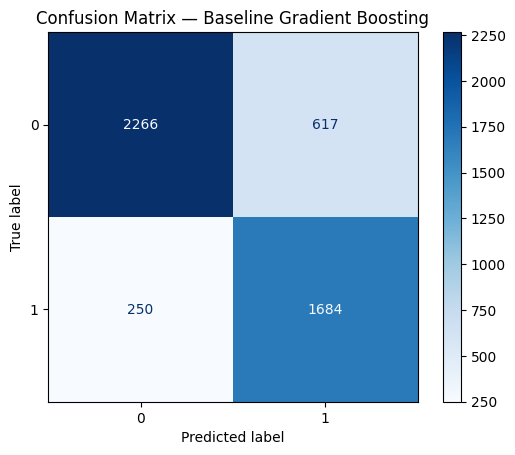

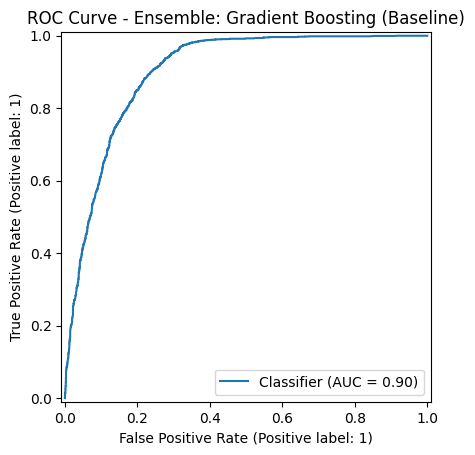

In [ ]:
gb_baseline = GradientBoostingClassifier(random_state=42)
gb_baseline.fit(X_train, y_train)

y_pred = gb_baseline.predict(X_test)
y_prob = gb_baseline.predict_proba(X_test)[:, 1]

evaluate_model(y_test, y_pred, y_prob, "Baseline Gradient Boosting")

RocCurveDisplay.from_predictions(y_test, y_prob)
plt.title("ROC Curve - Ensemble: Gradient Boosting (Baseline)")
plt.show()

Hyperparameter Tuning (Joint tuning)

three high-impact parameters:
- `n_estimators` - number of trees
- `learning_rate` - shrinkage factor
- `max_depth` - depth of each weak learner

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

n_estimators_list = [50, 100, 150, 200]
learning_rates    = [0.01, 0.05, 0.1, 0.2]
depth_values      = [1, 2, 3, 4]

best_gb_score = -1
best_gb_params = None

def cv_score(model, X, y):
    scores = []
    for train_idx, val_idx in cv.split(X, y):
        X_tr, X_val = X.iloc[train_idx], X.iloc[val_idx]
        y_tr, y_val = y.iloc[train_idx], y.iloc[val_idx]
        model.fit(X_tr, y_tr)
        scores.append(accuracy_score(y_val, model.predict(X_val)))
    return np.mean(scores)

for n in n_estimators_list:
    for lr in learning_rates:
        for d in depth_values:

            gb = GradientBoostingClassifier(
                n_estimators=n,
                learning_rate=lr,
                max_depth=d,
                random_state=42
            )

            val_score = cv_score(gb, X_train, y_train)

            if val_score > best_gb_score:
                best_gb_score = val_score
                best_gb_params = {
                    "n_estimators": n,
                    "learning_rate": lr,
                    "max_depth": d
                }

print("Best Gradient Boosting parameters:", best_gb_params)
print("Best Validation Accuracy:", best_gb_score)

Best Gradient Boosting parameters: {'n_estimators': 100, 'learning_rate': 0.05, 'max_depth': 4}
Best Validation Accuracy: 0.8178753546761491


Evaluate Tuned Gradient Boosting


===== Tuned Gradient Boosting =====
Accuracy:  0.8169
Precision: 0.7303
Recall:    0.8625
F1 Score:  0.7909
AUC:       0.8993

Confusion Matrix:
[[2267  616]
 [ 266 1668]]

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.79      0.84      2883
           1       0.73      0.86      0.79      1934

    accuracy                           0.82      4817
   macro avg       0.81      0.82      0.81      4817
weighted avg       0.83      0.82      0.82      4817



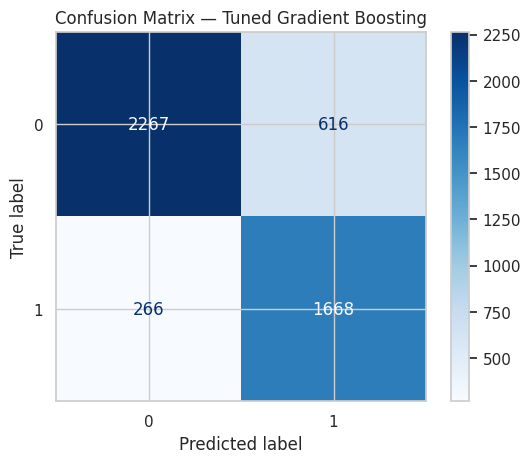

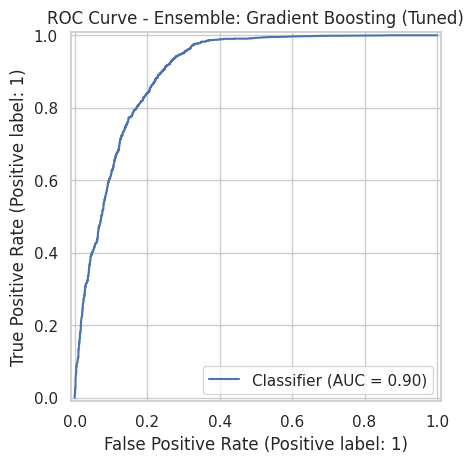

In [ ]:
gb_best = GradientBoostingClassifier(
    n_estimators=best_gb_params["n_estimators"],
    learning_rate=best_gb_params["learning_rate"],
    max_depth=best_gb_params["max_depth"],
    random_state=42
)

gb_best.fit(X_train, y_train)

y_pred_best = gb_best.predict(X_test)
y_prob_best = gb_best.predict_proba(X_test)[:, 1]

evaluate_model(
    y_test,
    y_pred_best,
    y_prob_best,
    "Tuned Gradient Boosting"
)

RocCurveDisplay.from_predictions(y_test, y_prob_best)
plt.title("ROC Curve - Ensemble: Gradient Boosting (Tuned)")
plt.show()

Feature Selection Loop

Best FS k for Gradient Boosting: 9


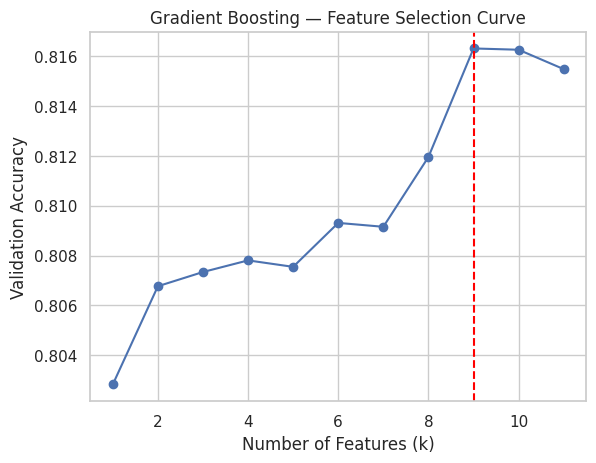

In [ ]:
fs_scores_gb = []
max_features = X_train.shape[1]

for k in range(1, max_features + 1):
    selector = SelectKBest(f_classif, k=k)
    X_train_fs = selector.fit_transform(X_train, y_train)
    X_train_fs = pd.DataFrame(X_train_fs)

    gb = GradientBoostingClassifier(random_state=42)
    score = cv_score(gb, X_train_fs, y_train)
    fs_scores_gb.append(score)

best_k_gb = np.argmax(fs_scores_gb) + 1
print("Best FS k for Gradient Boosting:", best_k_gb)

# Plot
plt.plot(range(1, max_features + 1), fs_scores_gb, marker='o')
plt.axvline(best_k_gb, color='red', linestyle='--')
plt.title("Gradient Boosting — Feature Selection Curve")
plt.xlabel("Number of Features (k)")
plt.ylabel("Validation Accuracy")
plt.grid(True)
plt.show()



In [ ]:
# Apply feature selection with best k
selector_fs_gb = SelectKBest(f_classif, k=best_k_gb)
X_train_fs = selector_fs_gb.fit_transform(X_train, y_train)
X_test_fs  = selector_fs_gb.transform(X_test)

X_train_fs = pd.DataFrame(X_train_fs)
X_test_fs  = pd.DataFrame(X_test_fs)

In [ ]:
# Tune GB Hyperparameters on FS-reduced dataset
best_fs_score = -1
best_fs_params = None

for n in n_estimators_list:
    for lr in learning_rates:
        for d in depth_values:

            gb = GradientBoostingClassifier(
                n_estimators=n,
                learning_rate=lr,
                max_depth=d,
                random_state=42
            )

            val = cv_score(gb, X_train_fs, y_train)

            if val > best_fs_score:
                best_fs_score = val
                best_fs_params = {
                    "n_estimators": n,
                    "learning_rate": lr,
                    "max_depth": d
                }

print("Best GB parameters after Feature Selection:", best_fs_params)


Best GB parameters after Feature Selection: {'n_estimators': 100, 'learning_rate': 0.1, 'max_depth': 4}



===== Gradient Boosting + Feature Selection =====
Accuracy:  0.8190
Precision: 0.7335
Recall:    0.8625
F1 Score:  0.7928
AUC:       0.9014

Confusion Matrix:
[[2277  606]
 [ 266 1668]]

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.79      0.84      2883
           1       0.73      0.86      0.79      1934

    accuracy                           0.82      4817
   macro avg       0.81      0.83      0.82      4817
weighted avg       0.83      0.82      0.82      4817



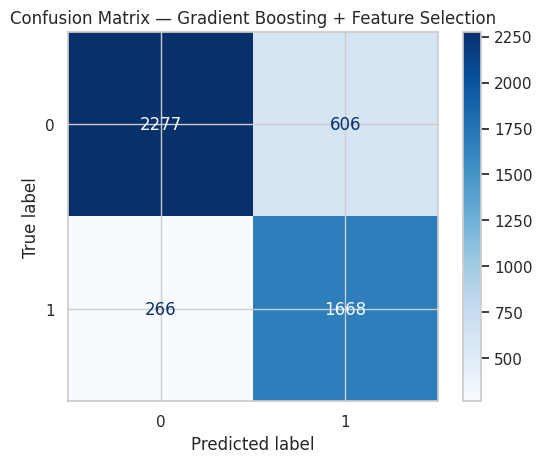

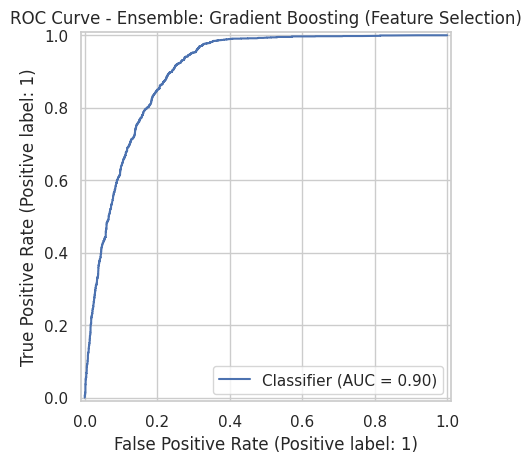

In [ ]:
# Final GB + Feature selection model
gb_fs = GradientBoostingClassifier(
    **best_fs_params,
    random_state=42
)

gb_fs.fit(X_train_fs, y_train)

y_pred_fs = gb_fs.predict(X_test_fs)
y_prob_fs = gb_fs.predict_proba(X_test_fs)[:, 1]

evaluate_model(y_test, y_pred_fs, y_prob_fs, "Gradient Boosting + Feature Selection")

RocCurveDisplay.from_predictions(y_test, y_prob_fs)
plt.title("ROC Curve - Ensemble: Gradient Boosting (Feature Selection)")
plt.show()


Final Model with Feature Selection

PCA (>= 90% variance) + Gradient Boosting

GB PCA components for ≥90 percent variance: 6


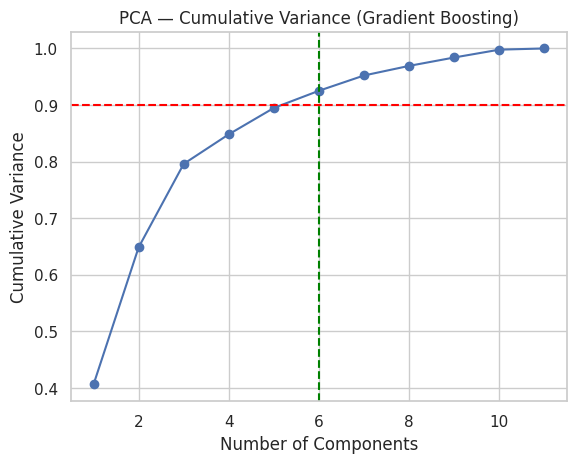

In [ ]:
pca_full = PCA().fit(X_train)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)

n_components_90_gb = np.argmax(cum_var >= 0.90) + 1
print("GB PCA components for ≥90 percent variance:", n_components_90_gb)

# Plot
plt.plot(range(1, len(cum_var)+1), cum_var, marker='o')
plt.axhline(0.90, color='red', linestyle='--')
plt.axvline(n_components_90_gb, color='green', linestyle='--')
plt.title("PCA — Cumulative Variance (Gradient Boosting)")
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Variance")
plt.grid(True)
plt.show()


In [ ]:
# Apply PCA
pca_gb = PCA(n_components=n_components_90_gb)
X_train_pca = pca_gb.fit_transform(X_train)
X_test_pca  = pca_gb.transform(X_test)

# Convert to DataFrame for CV indexing
X_train_pca = pd.DataFrame(X_train_pca)
X_test_pca  = pd.DataFrame(X_test_pca)


In [ ]:
# Tune GB Hyperparameters on PCA-reduced dataset

best_pca_score = -1
best_pca_params = None

for n in n_estimators_list:
    for lr in learning_rates:
        for d in depth_values:

            gb = GradientBoostingClassifier(
                n_estimators=n,
                learning_rate=lr,
                max_depth=d,
                random_state=42
            )

            val = cv_score(gb, X_train_pca, y_train)

            if val > best_pca_score:
                best_pca_score = val
                best_pca_params = {
                    "n_estimators": n,
                    "learning_rate": lr,
                    "max_depth": d
                }

print("Best GB parameters after PCA:", best_pca_params)


Best GB parameters after PCA: {'n_estimators': 200, 'learning_rate': 0.05, 'max_depth': 4}



===== Gradient Boosting + PCA =====
Accuracy:  0.7903
Precision: 0.7046
Recall:    0.8226
F1 Score:  0.7591
AUC:       0.8715

Confusion Matrix:
[[2216  667]
 [ 343 1591]]

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.77      0.81      2883
           1       0.70      0.82      0.76      1934

    accuracy                           0.79      4817
   macro avg       0.79      0.80      0.79      4817
weighted avg       0.80      0.79      0.79      4817



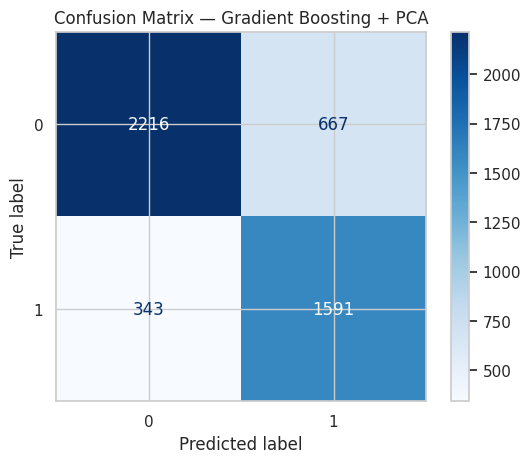

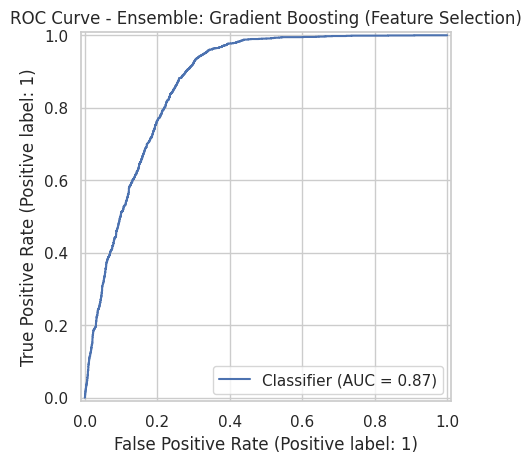

In [ ]:
# Final GB + PCA model

gb_pca = GradientBoostingClassifier(
    **best_pca_params,
    random_state=42
)

gb_pca.fit(X_train_pca, y_train)

y_pred_pca = gb_pca.predict(X_test_pca)
y_prob_pca = gb_pca.predict_proba(X_test_pca)[:, 1]

evaluate_model(y_test, y_pred_pca, y_prob_pca, "Gradient Boosting + PCA")

RocCurveDisplay.from_predictions(y_test, y_prob_pca)
plt.title("ROC Curve - Ensemble: Gradient Boosting (Feature Selection)")
plt.show()


##Summary:
Gradient Boosting was evaluated by training a baseline model and then tuning the three key hyperparameters through a manual cross-validation procedure. The tuned model delivered performance that was similar to the baseline, which suggests that the default settings already captured most of the useful structure in the dataset. Feature Selection was applied to identify the number of features that produced the highest validation accuracy, and the model was tuned again on this reduced feature set. PCA was also tested by selecting the number of components that preserved at least ninety percent of the variance and tuning the model on the transformed data. Both Feature Selection and PCA produced results that were close to the baseline model, but neither provided a clear improvement. Overall, Gradient Boosting delivered strong and stable performance across all settings, and the baseline configuration remained the best or nearly the best among the tested variations.